# Assignment 16: SVM, Trees, Ensembles, Validation & Unsupervised Learning

## 0. Environment Setup, Library Imports & Kaggle Dataset Loading

In this section, we import all authorized libraries, set visualization parameters, and ingest the Kaggle dataset from the local `breast_cancer.csv` file.


In [1]:
import os
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Suppress system warnings and configure joblib workers for clean outputs
os.environ["LOKY_MAX_CPU_COUNT"] = "4"
warnings.filterwarnings("ignore")

# Scikit-learn imports strictly adhering to coursework rules
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier, RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

# Supplementary Unsupervised Learning imports
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

# Configure high-resolution visual styling
sns.set_theme(style="whitegrid", font="sans-serif")
plt.rcParams["figure.dpi"] = 150
plt.rcParams["font.size"] = 10

print("[OK] All ML libraries imported successfully!")
print(f" - Scikit-Learn: {__import__('sklearn').__version__}")
print(f" - Pandas:       {pd.__version__}")
print(f" - NumPy:        {np.__version__}")


[OK] All ML libraries imported successfully!
 - Scikit-Learn: 1.9.0
 - Pandas:       3.0.3
 - NumPy:        2.5.5


### Ingesting and Auditing the Kaggle Breast Cancer Dataset
We load `breast_cancer.csv` and inspect its shape, column types, missing values, and target class balance.


In [2]:
# Load the Kaggle dataset
df = pd.read_csv("breast_cancer.csv")

# Dimensionality and data health checks
print(f"Dataset Shape: {df.shape[0]} rows x {df.shape[1]} columns")
print(f"Total Missing Values: {df.isnull().sum().sum()}")

# Separate Feature Matrix (X) and Target Vector (y)
X = df.drop(columns=['target'])
y = df['target']
feature_names = X.columns.tolist()
class_names = ["Malignant", "Benign"]

# Class distribution
counts = y.value_counts()
print(f"Class 0 (Malignant): {counts[0]} ({counts[0]/len(df)*100:.2f}%)")
print(f"Class 1 (Benign):    {counts[1]} ({counts[1]/len(df)*100:.2f}%)")
print(f"Features (first 5):  {feature_names[:5]}")
df.head(3)


Dataset Shape: 569 rows x 31 columns
Total Missing Values: 0
Class 0 (Malignant): 212 (37.26%)
Class 1 (Benign):    357 (62.74%)
Features (first 5):  ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness']


## PART 1 — Advanced Supervised Algorithms
### Task 1: Support Vector Machine (SVM)

SVM (Linear Kernel) Accuracy: 97.37% | F1-Score: 0.9790
SVM (RBF Kernel)    Accuracy: 98.25% | F1-Score: 0.9861
Accuracy Delta (RBF - Linear): +0.88%

SVM (Linear Kernel) Classification Report:
              precision    recall  f1-score   support

   Malignant     0.9535    0.9762    0.9647        42
      Benign     0.9859    0.9722    0.9790        72

    accuracy                         0.9737       114
   macro avg     0.9697    0.9742    0.9719       114
weighted avg     0.9740    0.9737    0.9737       114

SVM (RBF Kernel) Classification Report:
              precision    recall  f1-score   support

   Malignant     0.9762    0.9762    0.9762        42
      Benign     0.9861    0.9861    0.9861        72

    accuracy                         0.9825       114
   macro avg     0.9812    0.9812    0.9812       114
weighted avg     0.9825    0.9825    0.9825       114


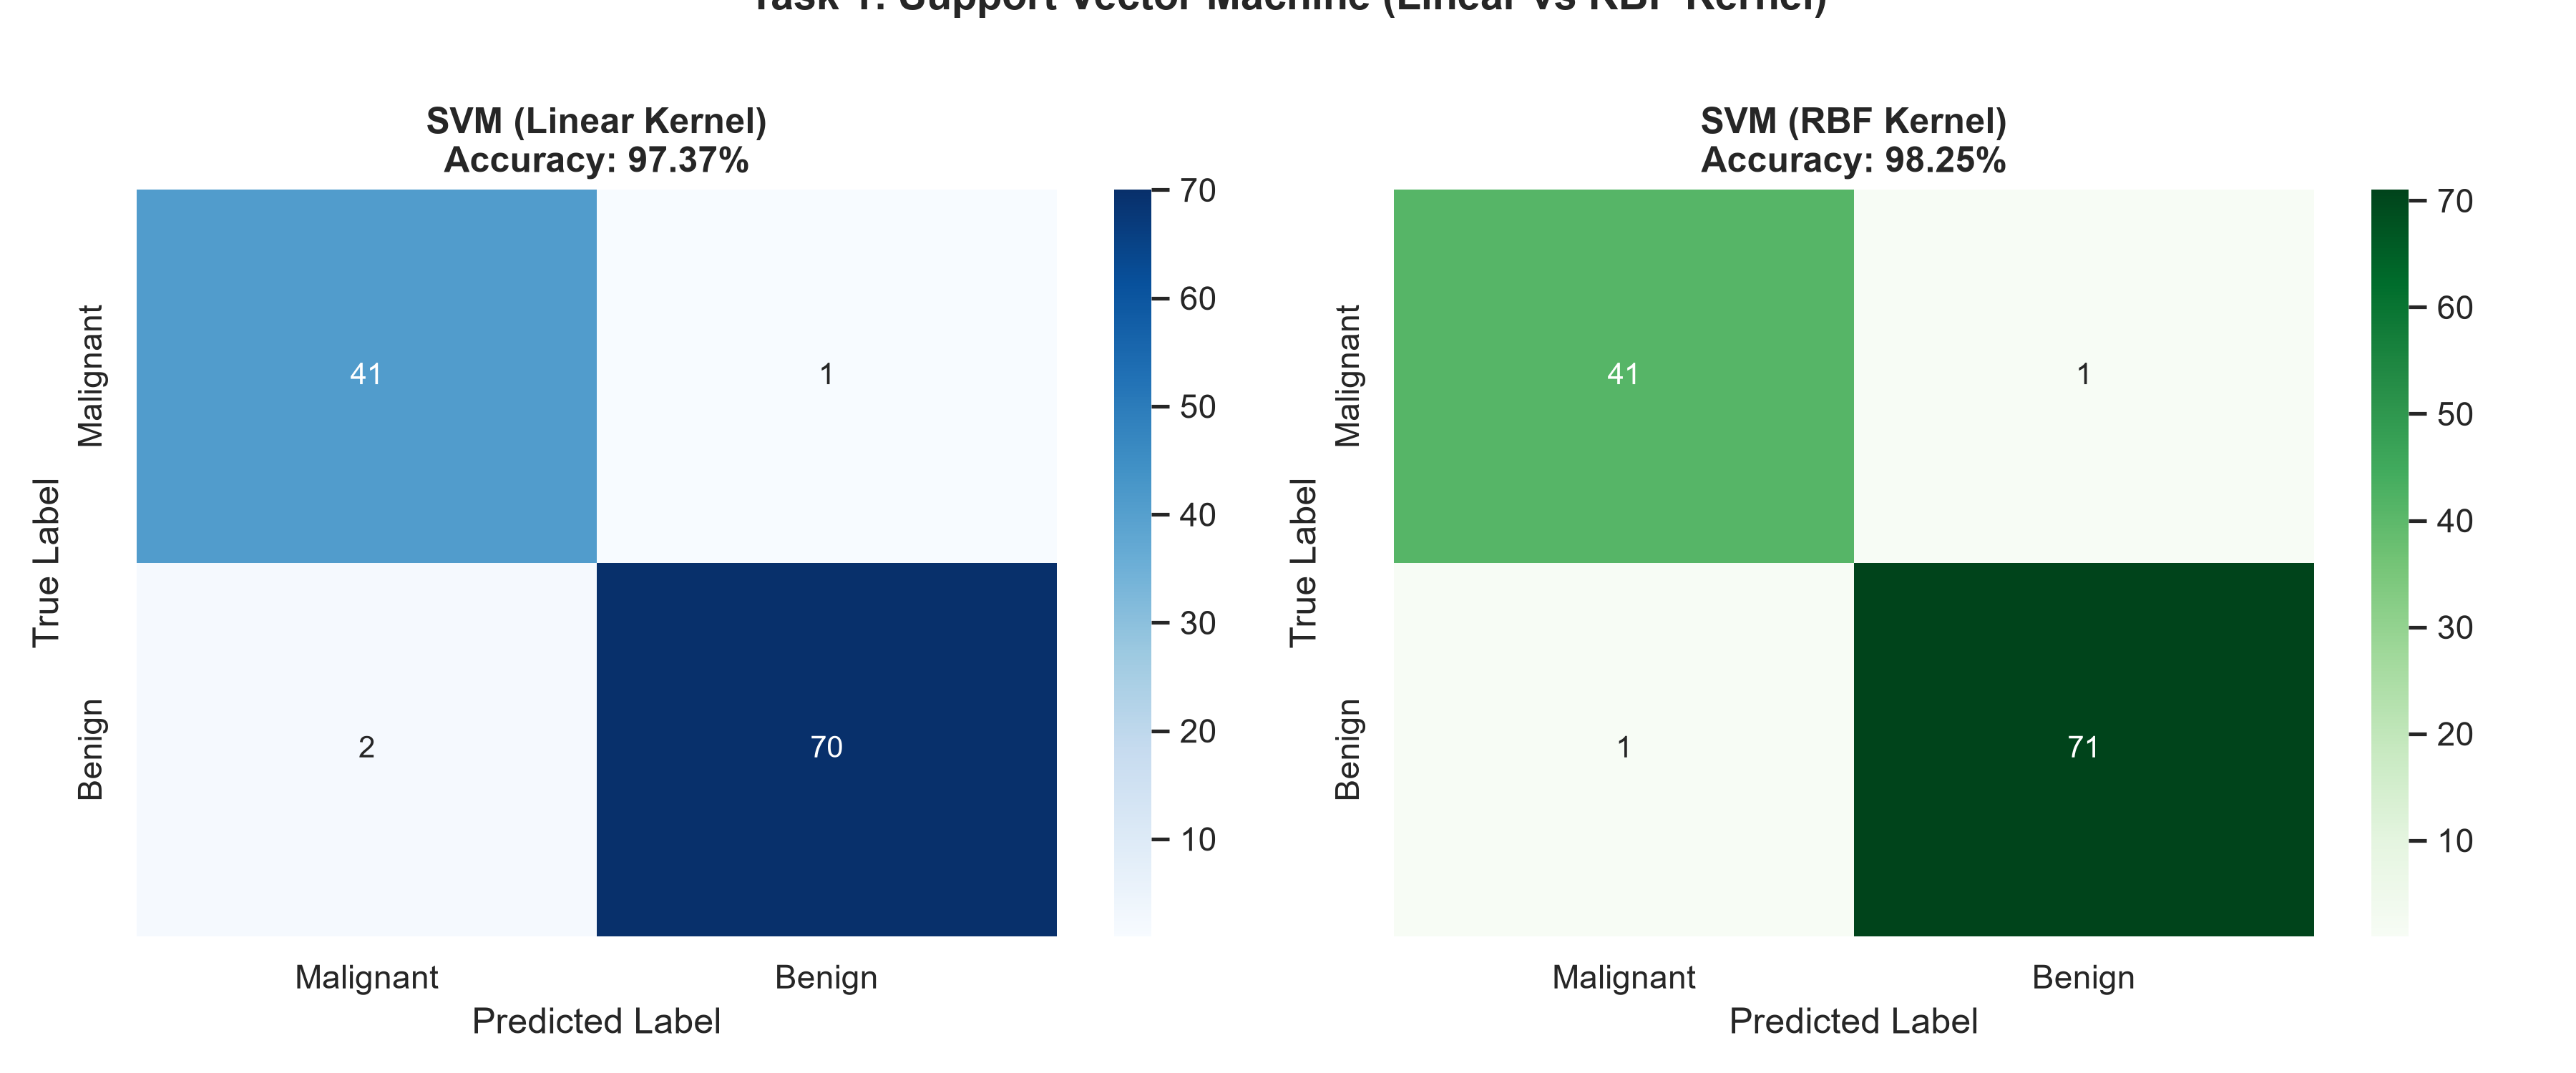

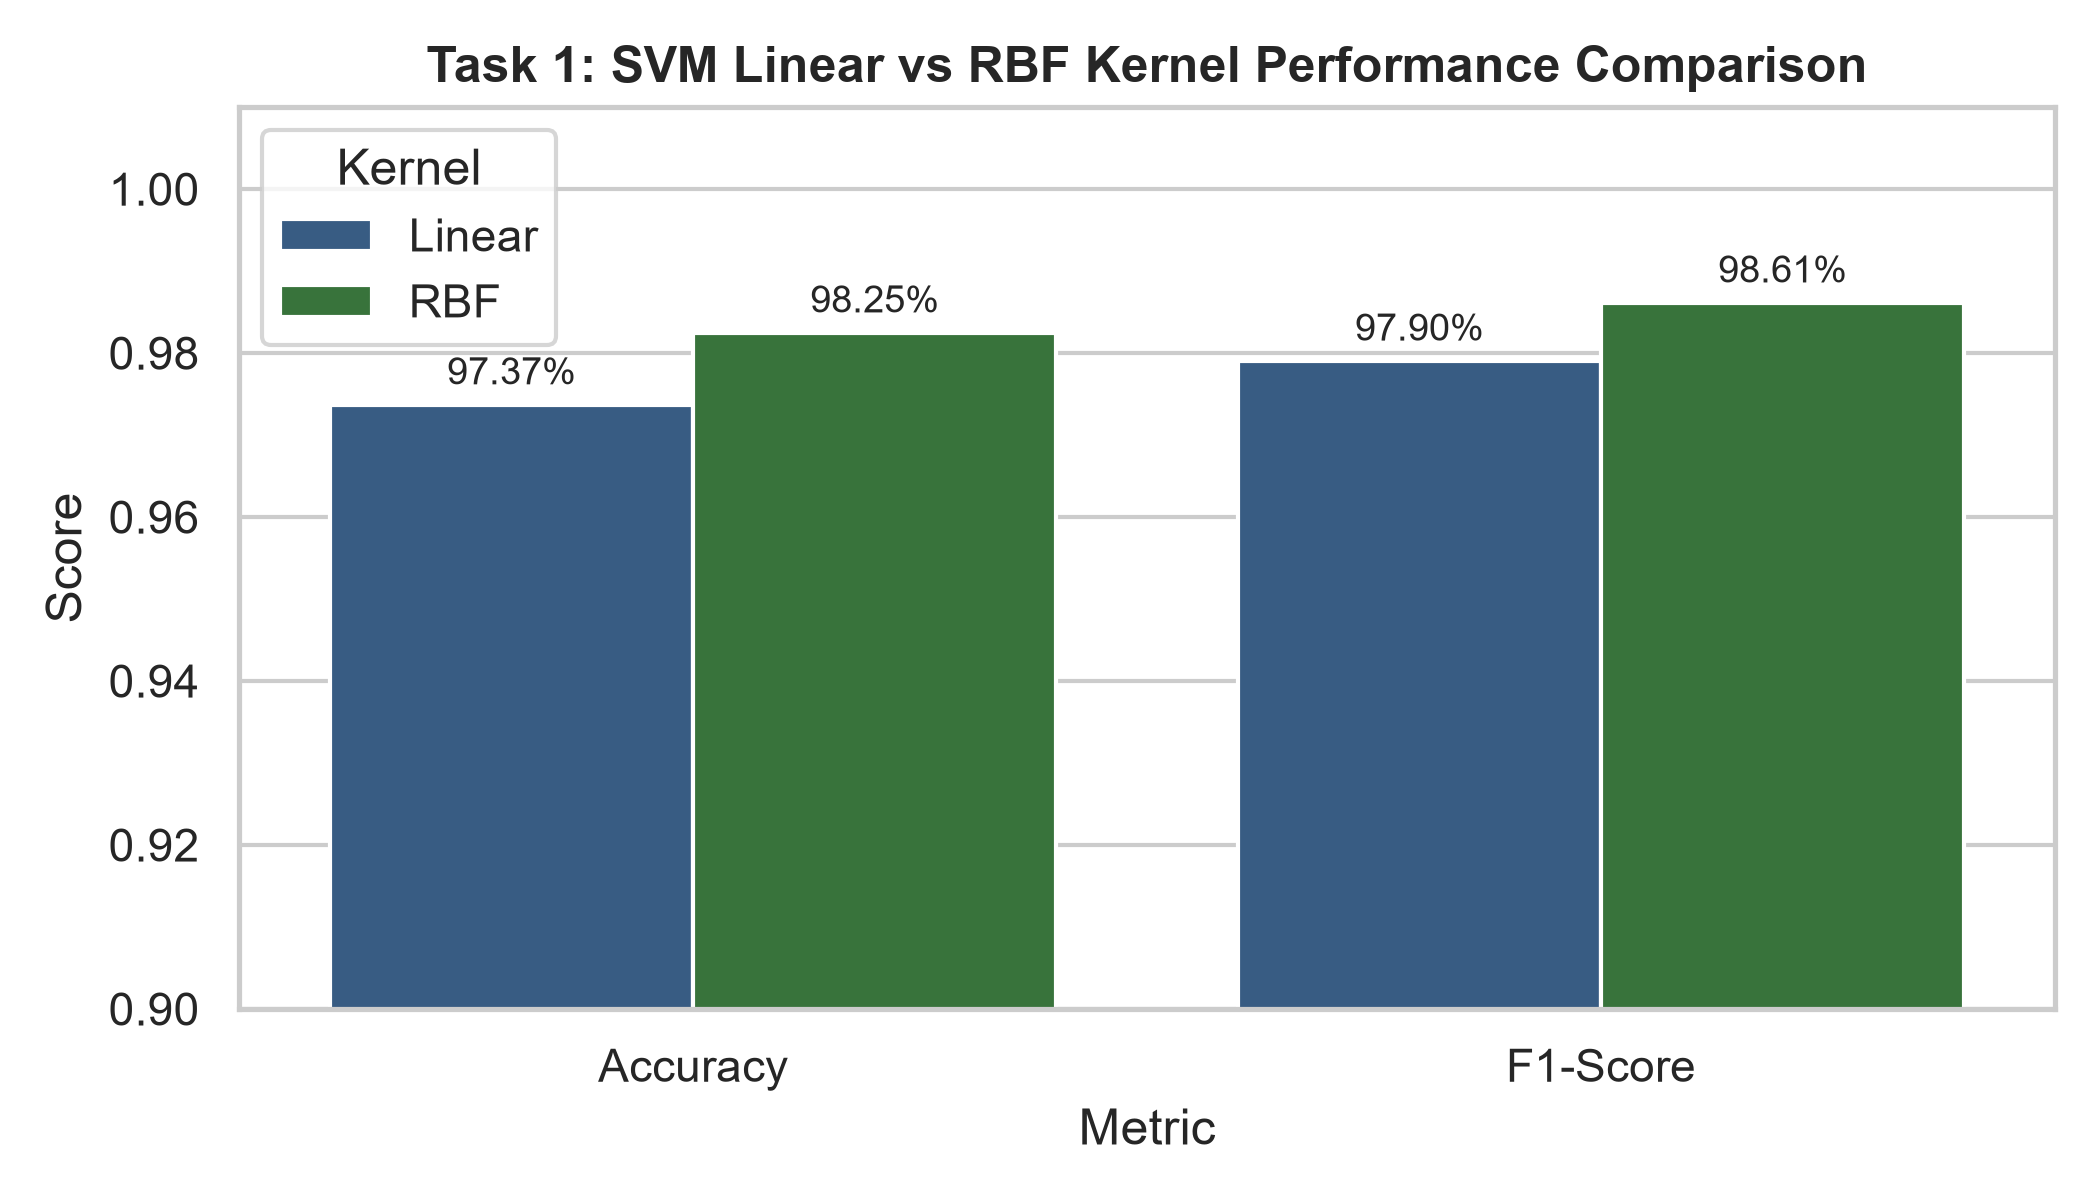

In [3]:
# 1. Stratified Train-Test Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 2. Standardization via StandardScaler (fit on train, transform on test)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Train SVM with Linear Kernel
svm_linear = SVC(kernel='linear', C=1.0, random_state=42)
svm_linear.fit(X_train_scaled, y_train)
y_pred_linear = svm_linear.predict(X_test_scaled)
acc_linear = accuracy_score(y_test, y_pred_linear)
f1_linear = f1_score(y_test, y_pred_linear)

# 4. Train SVM with RBF Kernel
svm_rbf = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
svm_rbf.fit(X_train_scaled, y_train)
y_pred_rbf = svm_rbf.predict(X_test_scaled)
acc_rbf = accuracy_score(y_test, y_pred_rbf)
f1_rbf = f1_score(y_test, y_pred_rbf)

# 5. Performance Comparison
print(f"SVM (Linear Kernel) Accuracy: {acc_linear * 100:.2f}% | F1-Score: {f1_linear:.4f}")
print(f"SVM (RBF Kernel)    Accuracy: {acc_rbf * 100:.2f}% | F1-Score: {f1_rbf:.4f}")
print(f"Accuracy Delta (RBF - Linear): {(acc_rbf - acc_linear) * 100:+.2f}%\n")

print("SVM (Linear Kernel) Classification Report:")
print(classification_report(y_test, y_pred_linear, target_names=class_names, digits=4))

print("SVM (RBF Kernel) Classification Report:")
print(classification_report(y_test, y_pred_rbf, target_names=class_names, digits=4))

# Visualizing Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
cm_linear = confusion_matrix(y_test, y_pred_linear)
cm_rbf = confusion_matrix(y_test, y_pred_rbf)

sns.heatmap(cm_linear, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=class_names, yticklabels=class_names)
axes[0].set_title(f"SVM (Linear Kernel)\nAccuracy: {acc_linear*100:.2f}%", fontweight='bold')
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

sns.heatmap(cm_rbf, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=class_names, yticklabels=class_names)
axes[1].set_title(f"SVM (RBF Kernel)\nAccuracy: {acc_rbf*100:.2f}%", fontweight='bold')
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")

plt.suptitle("Task 1: Support Vector Machine (Linear vs RBF Kernel)", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


#### Task 1 Analysis & Mathematical Insights:


### Task 2: Decision Tree Algorithm & Bias-Variance Tradeoff
#### 1. Underfitting vs. Overfitting Mechanics:

Depth-Limited Tree (max_depth=3) -> Train Acc: 97.58% | Test Acc: 93.86%

Decision Tree Split Rules (Root & Subtrees):
|--- worst radius <= 16.80
|   |--- worst concave points <= 0.14
|   |   |--- area error <= 91.56
|   |   |   |--- class: 1
|   |   |--- area error >  91.56
|   |   |   |--- class: 0
|   |--- worst concave points >  0.14
|   |   |--- worst texture <= 25.62
|   |   |   |--- class: 1
|   |   |--- worst texture >  25.62
|   |   |   |--- class: 0
|--- worst radius >  16.80
|   |--- texture error <= 0.47
|   |   |--- class: 1


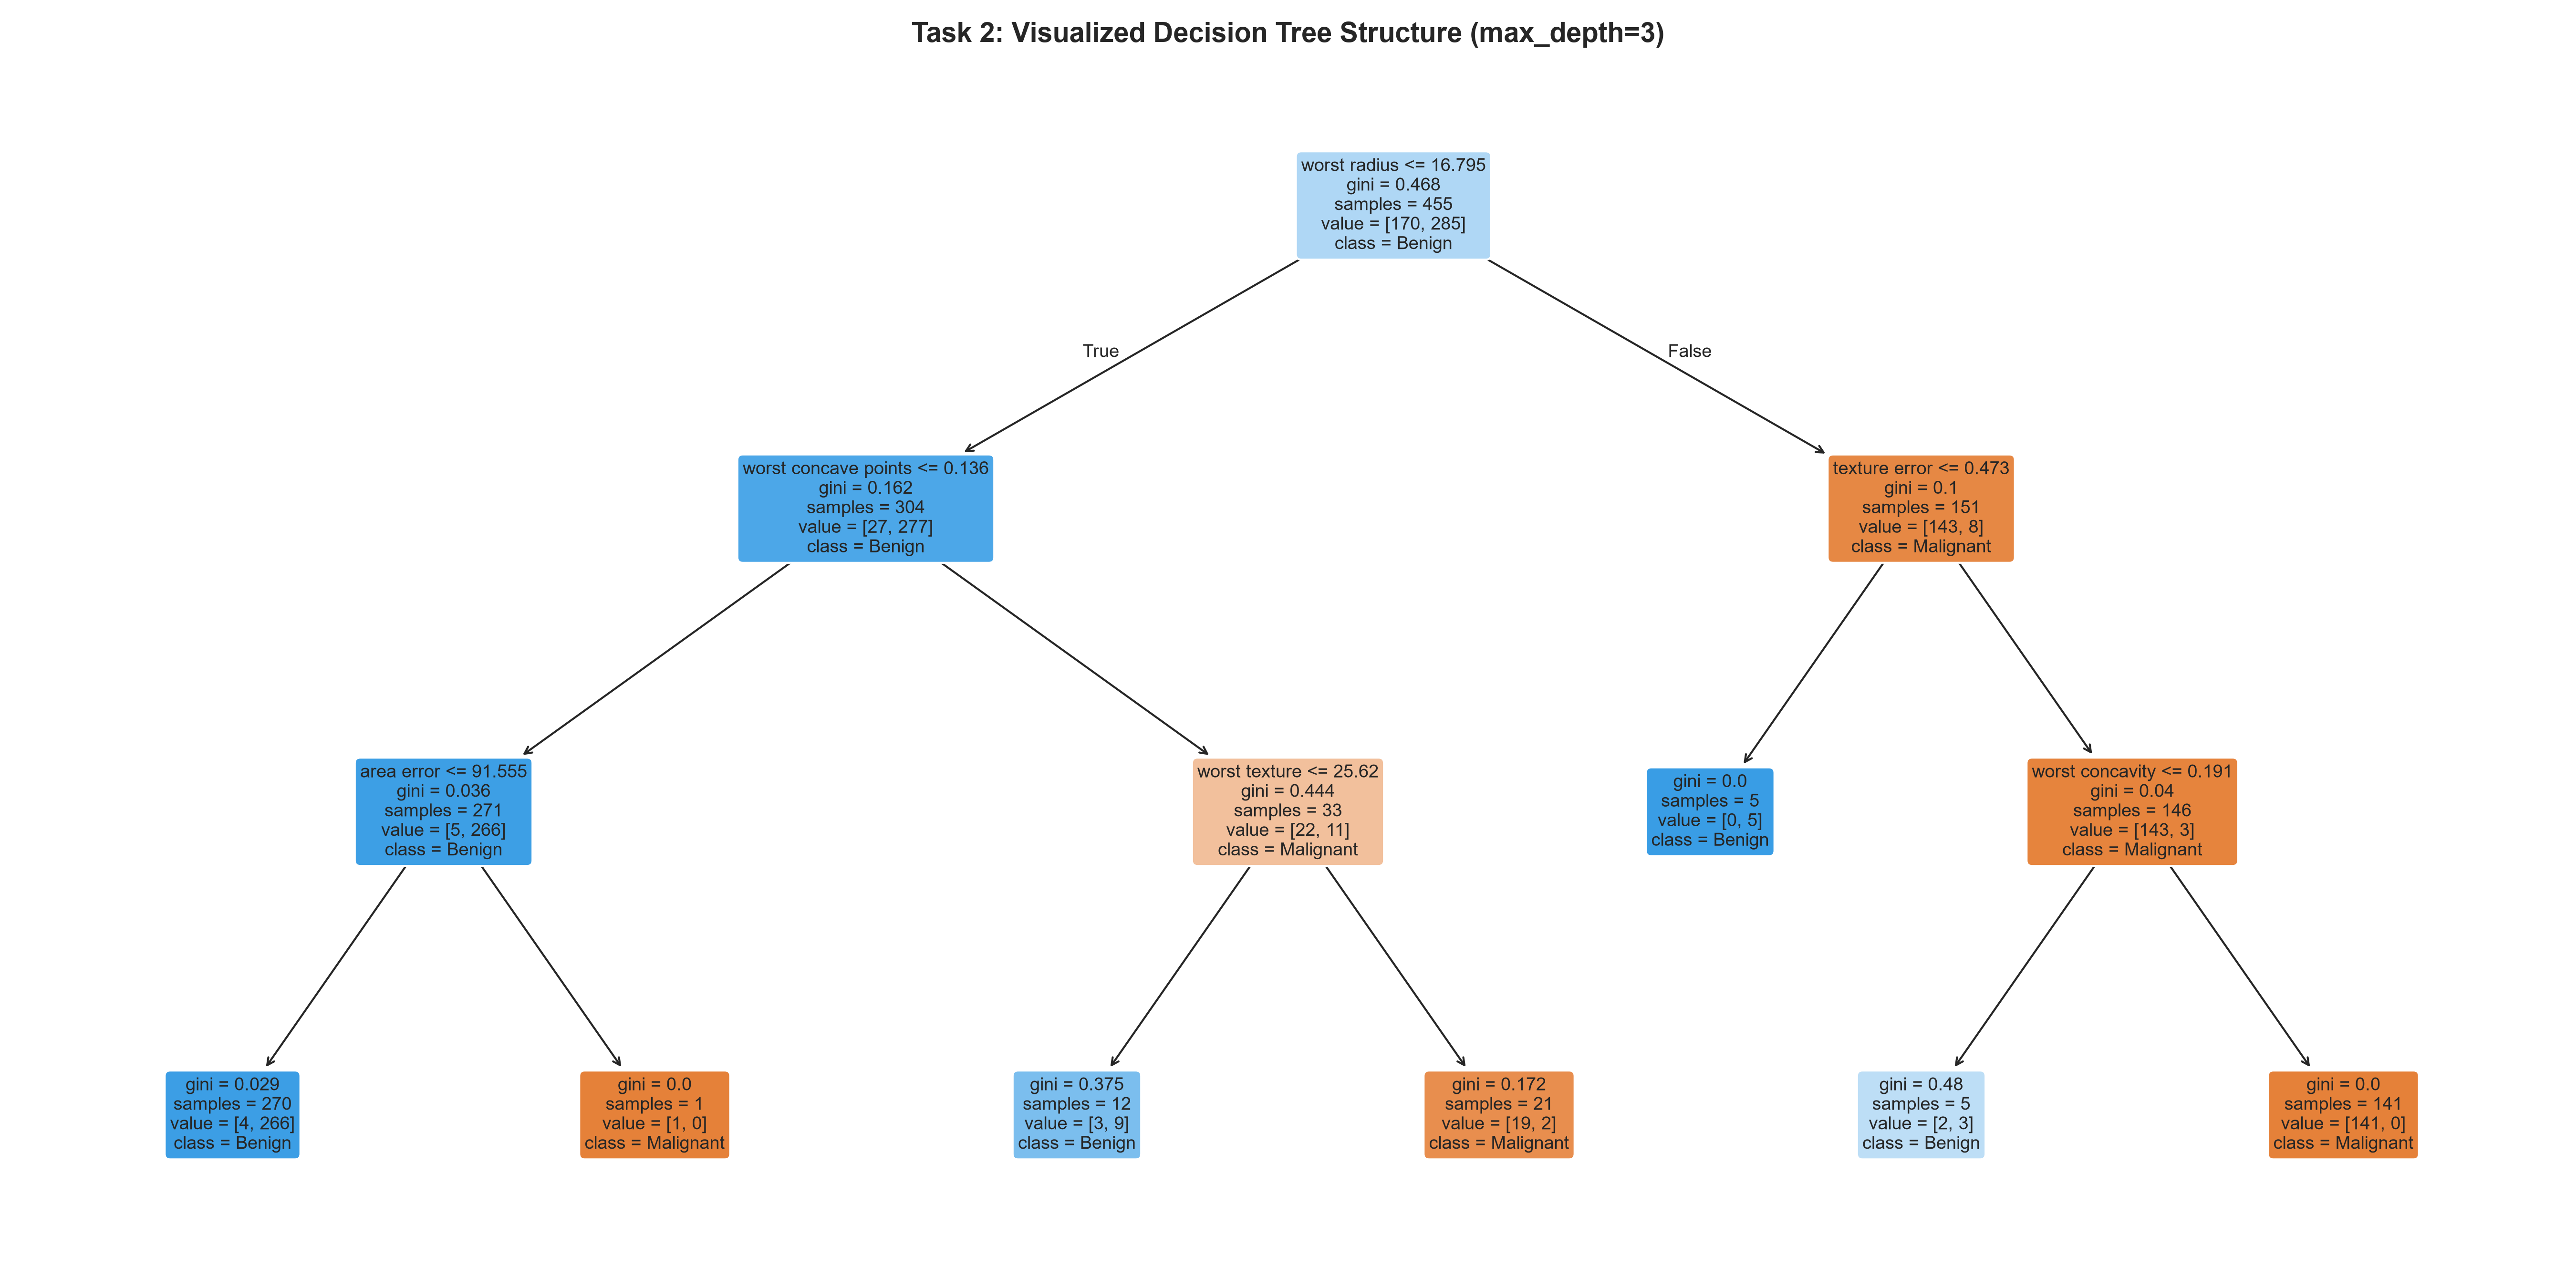

In [4]:
# 1. Train Depth-Limited Decision Tree (max_depth=3) for visual inspection
dt_limited = DecisionTreeClassifier(max_depth=3, criterion='gini', random_state=42)
dt_limited.fit(X_train, y_train)

train_acc_lim = accuracy_score(y_train, dt_limited.predict(X_train))
test_acc_lim = accuracy_score(y_test, dt_limited.predict(X_test))
print(f"Depth-Limited Tree (max_depth=3) -> Train Acc: {train_acc_lim*100:.2f}% | Test Acc: {test_acc_lim*100:.2f}%\n")

# 2. Visualize Decision Tree Structure
plt.figure(figsize=(16, 8))
plot_tree(
    dt_limited,
    feature_names=feature_names,
    class_names=class_names,
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("Task 2: Decision Tree Architecture (max_depth=3)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Print textual rules for the tree
print("Decision Tree Split Rules (Root & Subtrees):")
print(export_text(dt_limited, feature_names=feature_names, max_depth=3))


--- Comparison of Underfitting vs Depth-Limited vs Overfitting ---
Underfitting Model (max_depth=1)   : Train Acc = 92.31%, Test Acc = 92.11% (High Bias)
Depth-Limited Model (max_depth=3)  : Train Acc = 97.58%, Test Acc = 93.86% (Optimal Tradeoff)
Overfitting Model   (max_depth=None): Train Acc = 100.00%, Test Acc = 91.23% (High Variance)
Generalization Overfitting Gap (Train - Test): 8.77%


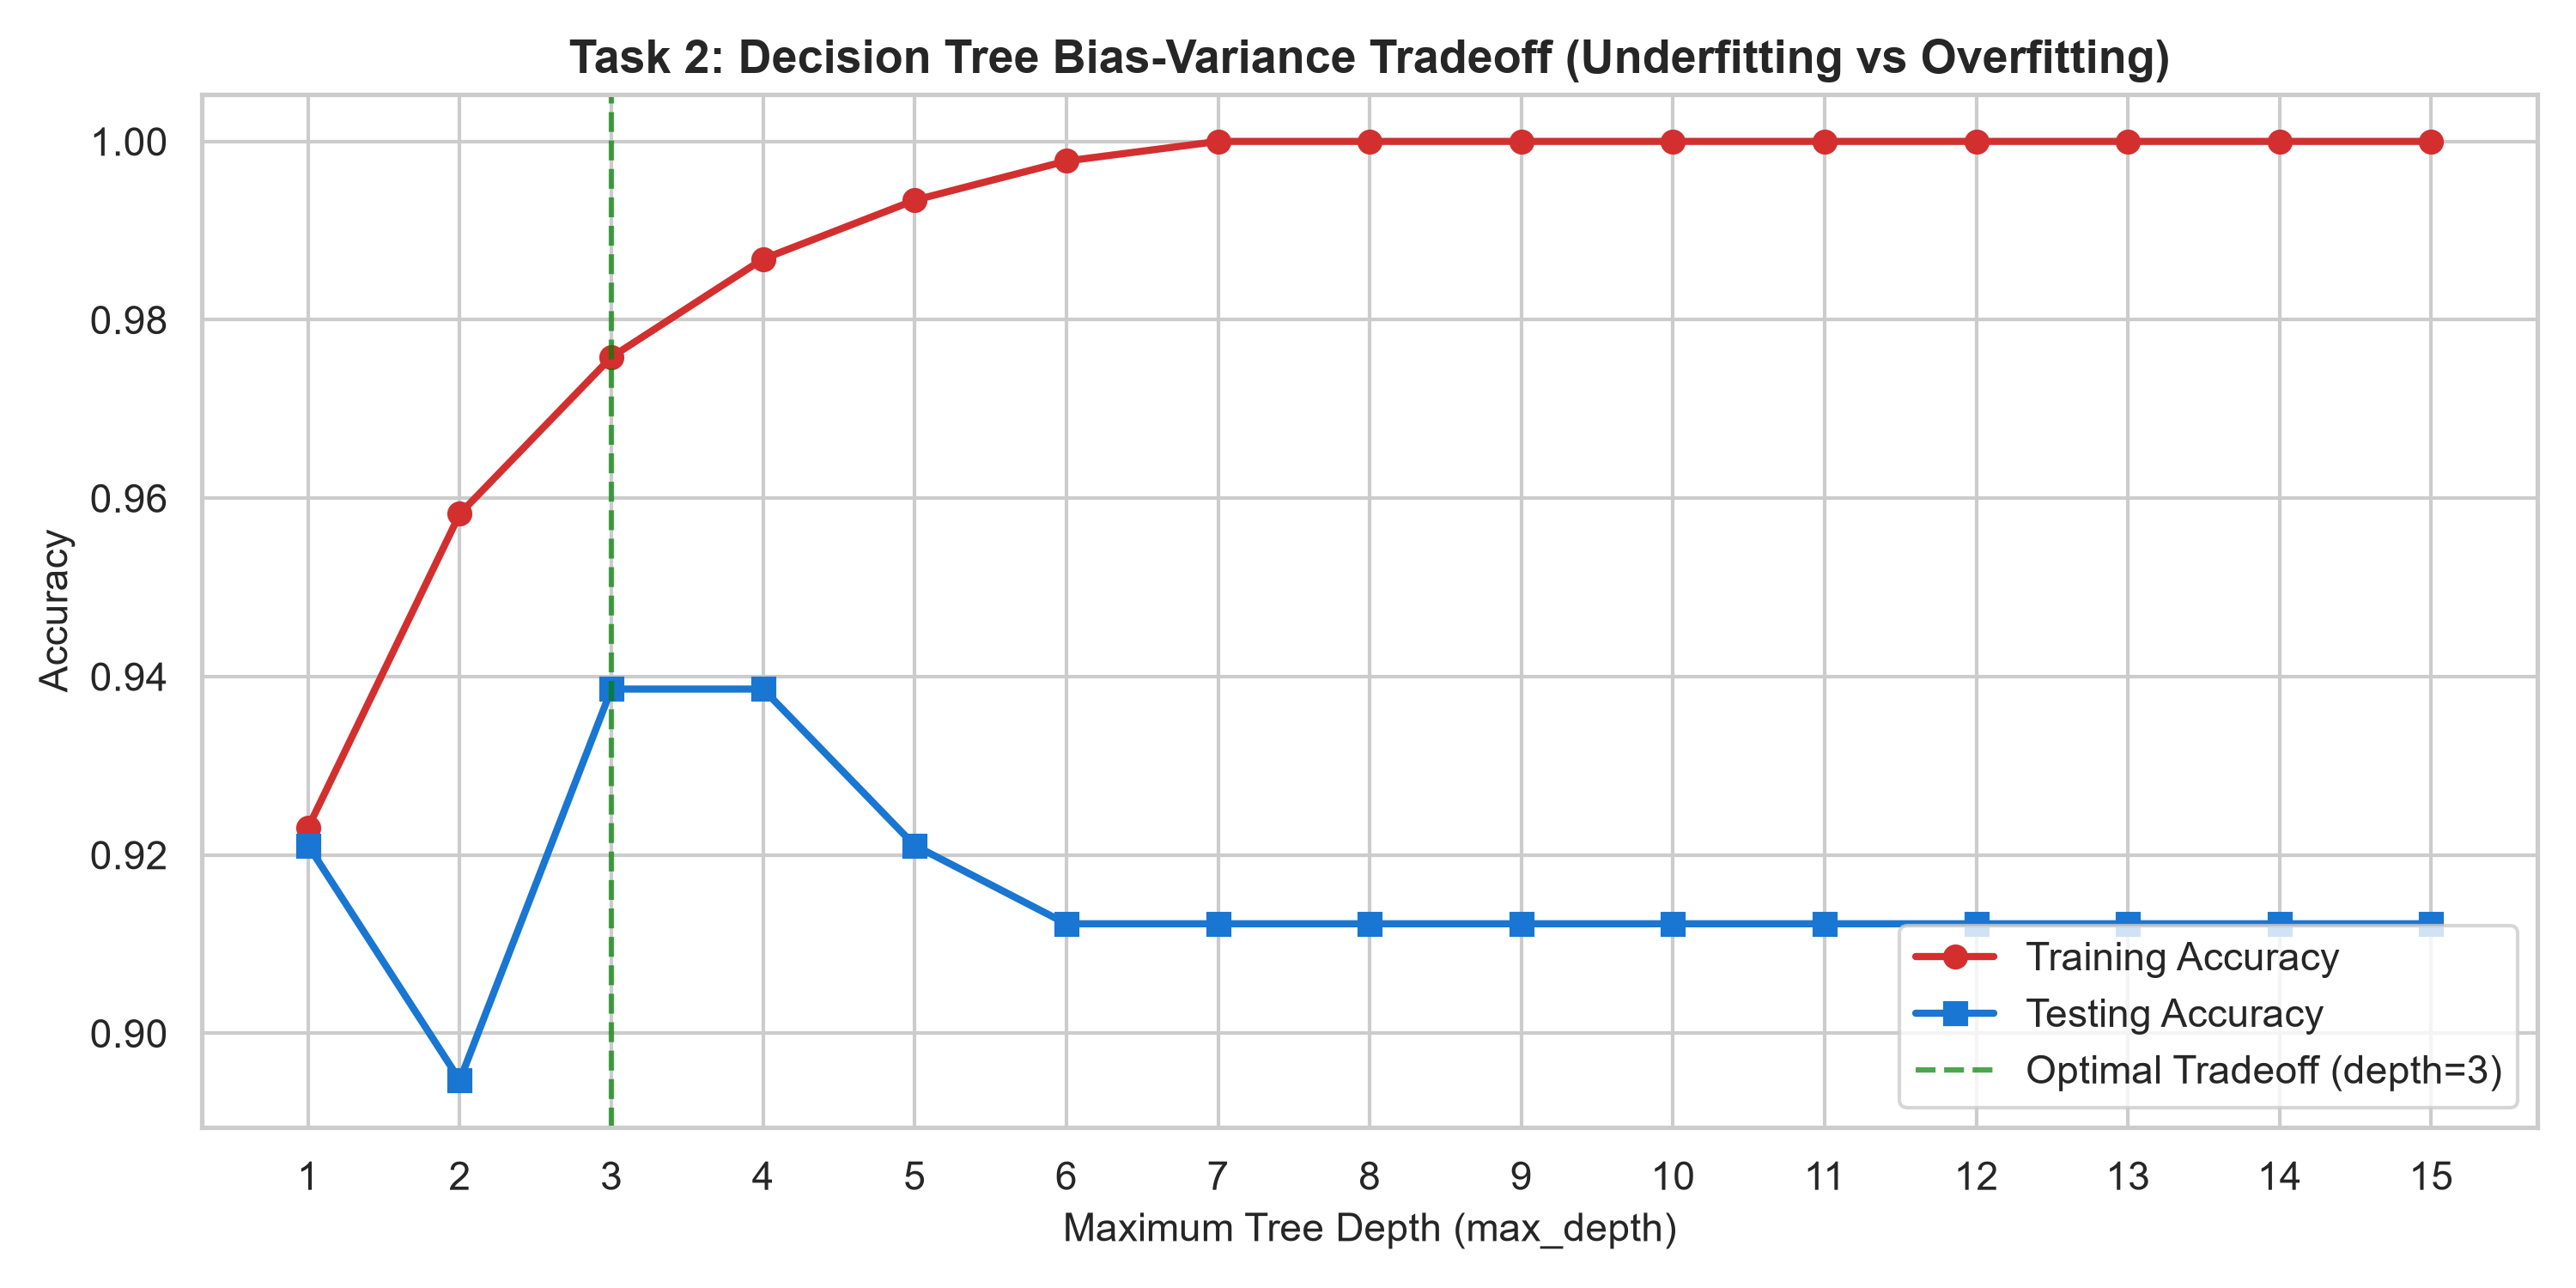

In [5]:
# 3. Train Underfitting Model (Low max_depth = 1, Decision Stump)
dt_underfit = DecisionTreeClassifier(max_depth=1, criterion='gini', random_state=42)
dt_underfit.fit(X_train, y_train)
train_acc_under = accuracy_score(y_train, dt_underfit.predict(X_train))
test_acc_under = accuracy_score(y_test, dt_underfit.predict(X_test))

# 4. Train Overfitting Model (High max_depth = None, unconstrained splits)
dt_overfit = DecisionTreeClassifier(max_depth=None, criterion='gini', min_samples_split=2, random_state=42)
dt_overfit.fit(X_train, y_train)
train_acc_over = accuracy_score(y_train, dt_overfit.predict(X_train))
test_acc_over = accuracy_score(y_test, dt_overfit.predict(X_test))

print("--- Comparison of Underfitting vs Depth-Limited vs Overfitting ---")
print(f"Underfitting Model (max_depth=1)   : Train Acc = {train_acc_under*100:.2f}%, Test Acc = {test_acc_under*100:.2f}% (High Bias)")
print(f"Depth-Limited Model (max_depth=3)  : Train Acc = {train_acc_lim*100:.2f}%, Test Acc = {test_acc_lim*100:.2f}% (Optimal Tradeoff)")
print(f"Overfitting Model   (max_depth=None): Train Acc = {train_acc_over*100:.2f}%, Test Acc = {test_acc_over*100:.2f}% (High Variance)")
print(f"Generalization Overfitting Gap (Train - Test): {(train_acc_over - test_acc_over)*100:.2f}%\n")

# 5. Sweep max_depth from 1 to 15 to plot the Bias-Variance Tradeoff Curve
depths = list(range(1, 16))
train_scores = []
test_scores = []

for d in depths:
    clf = DecisionTreeClassifier(max_depth=d, criterion='gini', random_state=42)
    clf.fit(X_train, y_train)
    train_scores.append(accuracy_score(y_train, clf.predict(X_train)))
    test_scores.append(accuracy_score(y_test, clf.predict(X_test)))

plt.figure(figsize=(9, 4.5))
plt.plot(depths, train_scores, marker='o', color='#d32f2f', linewidth=2, label="Training Accuracy (Memorization)")
plt.plot(depths, test_scores, marker='s', color='#1976d2', linewidth=2, label="Testing Accuracy (Generalization)")
plt.axvline(x=3, color='green', linestyle='--', label='Sweet Spot (max_depth=3)')
plt.title("Task 2: Decision Tree Bias-Variance Tradeoff Curve", fontsize=12, fontweight='bold')
plt.xlabel("Maximum Tree Depth (max_depth)")
plt.ylabel("Accuracy")
plt.xticks(depths)
plt.legend()
plt.tight_layout()
plt.show()


## PART 2 — Model Validation & Cross-Validation
### Task 3: Train vs Validation vs Test Split (3-Way Partitioning)

Training Set:   341 samples (59.9%)
Validation Set: 114 samples (20.0%)
Test Set:       114 samples (20.0%)

Tuning max_depth on Validation Set:
 - max_depth= 1 | Train: 92.67% | Val: 89.47%
 - max_depth= 2 | Train: 96.77% | Val: 94.74%
 - max_depth= 3 | Train: 97.36% | Val: 93.86%
 - max_depth= 4 | Train: 98.53% | Val: 93.86%
 - max_depth= 5 | Train: 99.71% | Val: 95.61%
 - max_depth= 6 | Train: 100.00% | Val: 95.61%
 - max_depth= 7 | Train: 100.00% | Val: 95.61%
 - max_depth= 8 | Train: 100.00% | Val: 95.61%
 - max_depth=10 | Train: 100.00% | Val: 95.61%
 - max_depth=12 | Train: 100.00% | Val: 95.61%
 - max_depth=15 | Train: 100.00% | Val: 95.61%

[OPTIMAL HYPERPARAMETER] Selected max_depth = 5 (Validation Accuracy = 95.61%)

Final Model Test Evaluation (Evaluated Once on Test Set):
 - Final Test Accuracy: 92.11%
 - Final Test F1-Score: 0.9362


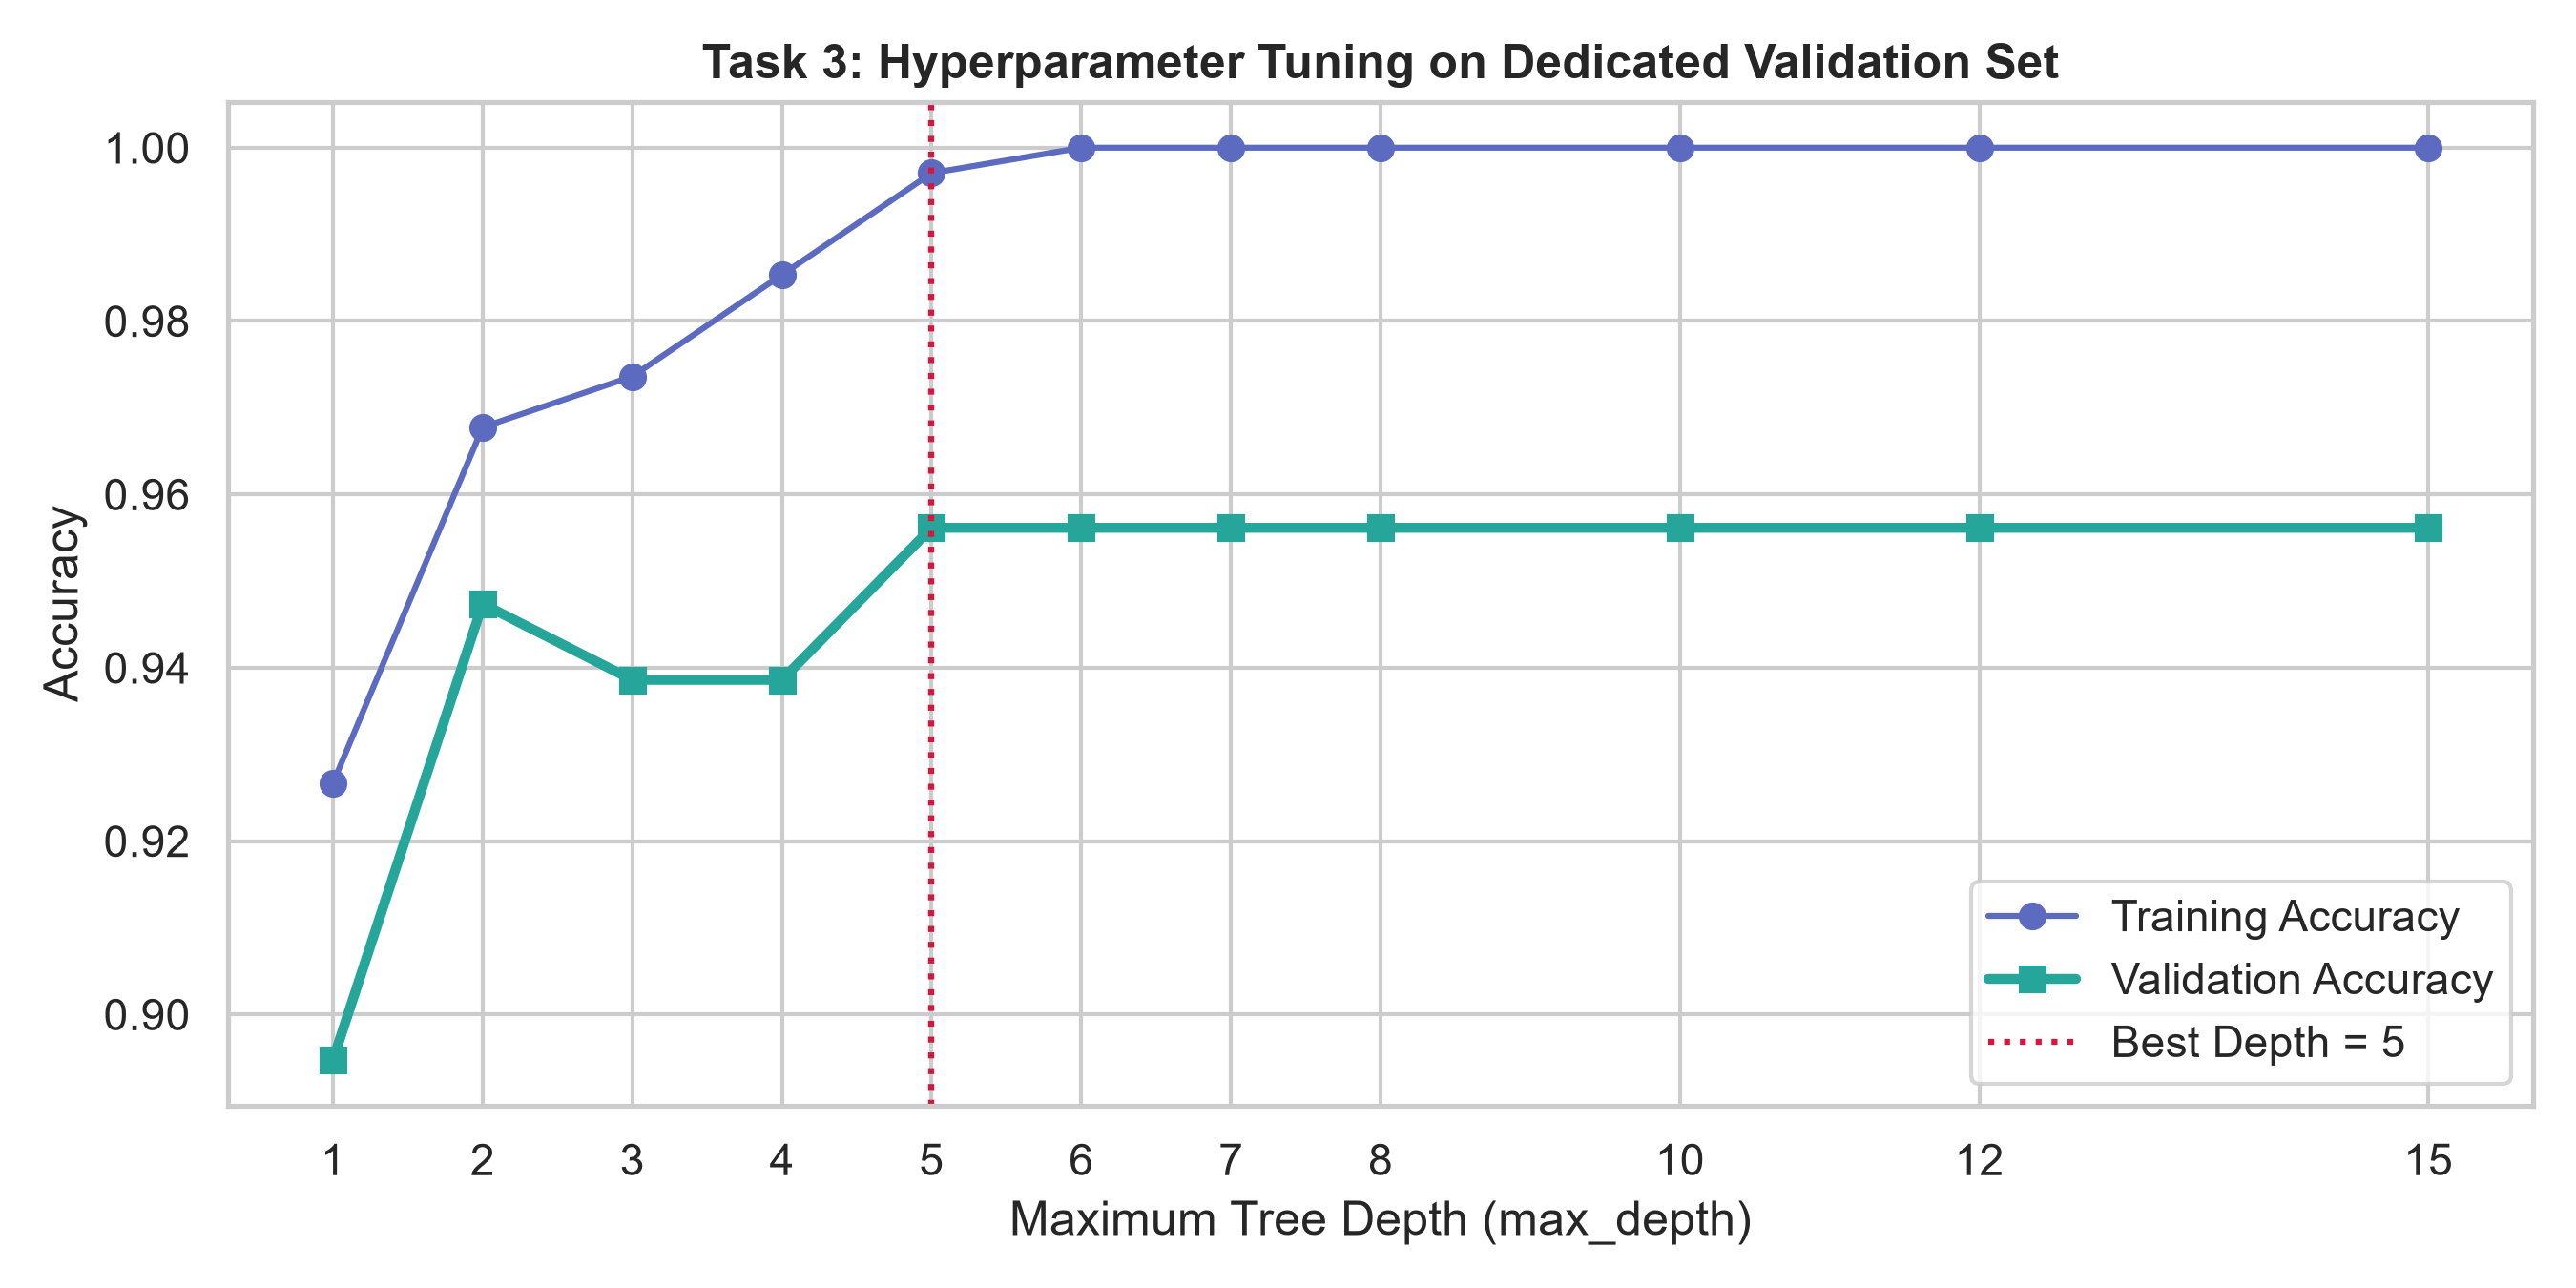

In [6]:
# 1. Two-step Partitioning to achieve exact 60% Train, 20% Val, 20% Test
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, random_state=42, stratify=y_train_val
)

print(f"Training Set:   {X_train.shape[0]} samples ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"Validation Set: {X_val.shape[0]} samples ({X_val.shape[0]/len(X)*100:.1f}%)")
print(f"Test Set:       {X_test.shape[0]} samples ({X_test.shape[0]/len(X)*100:.1f}%)\n")

# 2 & 3. Systematic Hyperparameter Tuning on Validation Set
candidate_depths = [1, 2, 3, 4, 5, 6, 7, 8, 10, 12, 15]
val_accuracies = []
train_accuracies = []
best_val_acc = -1.0
best_depth = None

print("Tuning max_depth on Validation Set:")
for d in candidate_depths:
    clf = DecisionTreeClassifier(max_depth=d, criterion='gini', random_state=42)
    clf.fit(X_train, y_train)
    t_acc = accuracy_score(y_train, clf.predict(X_train))
    v_acc = accuracy_score(y_val, clf.predict(X_val))
    train_accuracies.append(t_acc)
    val_accuracies.append(v_acc)
    print(f" - max_depth={d:2d} | Train: {t_acc*100:.2f}% | Val: {v_acc*100:.2f}%")
    if v_acc > best_val_acc:
        best_val_acc = v_acc
        best_depth = d

print(f"\n[OPTIMAL HYPERPARAMETER] Selected max_depth = {best_depth} (Validation Accuracy = {best_val_acc*100:.2f}%)")

# 4. Final Evaluation on Untouched Test Set
final_model = DecisionTreeClassifier(max_depth=best_depth, criterion='gini', random_state=42)
final_model.fit(X_train_val, y_train_val)
test_pred = final_model.predict(X_test)
final_test_acc = accuracy_score(y_test, test_pred)
final_test_f1 = f1_score(y_test, test_pred)

print(f"\nFinal Model Test Evaluation (Evaluated Once on Test Set):")
print(f" - Final Test Accuracy: {final_test_acc * 100:.2f}%")
print(f" - Final Test F1-Score: {final_test_f1:.4f}")

# Plot Validation Curve
plt.figure(figsize=(8, 4))
plt.plot(candidate_depths, train_accuracies, marker='o', label="Training Accuracy", color="#5c6bc0")
plt.plot(candidate_depths, val_accuracies, marker='s', label="Validation Accuracy", color="#26a69a", linewidth=2.5)
plt.axvline(x=best_depth, color='crimson', linestyle=':', label=f"Best Depth = {best_depth}")
plt.title("Task 3: Parameter Tuning on Validation Set", fontweight='bold')
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.xticks(candidate_depths)
plt.legend()
plt.tight_layout()
plt.show()


### Task 4: Cross-Validation ($k=5$) vs. Single Train-Test Split

5-Fold Cross-Validation Individual Scores:
 - Fold 1: 93.86%
 - Fold 2: 88.60%
 - Fold 3: 92.98%
 - Fold 4: 92.98%
 - Fold 5: 95.58%

Average CV Accuracy: 92.80% (+/- 2.30%)
95% Confidence Interval: [0.8830, 0.9730]

--- Variance & Generalization Comparison ---
Single Train-Test Split Accuracy: 92.11%
5-Fold Cross-Validation Mean Acc: 92.80%
Empirical Difference:             -0.69%


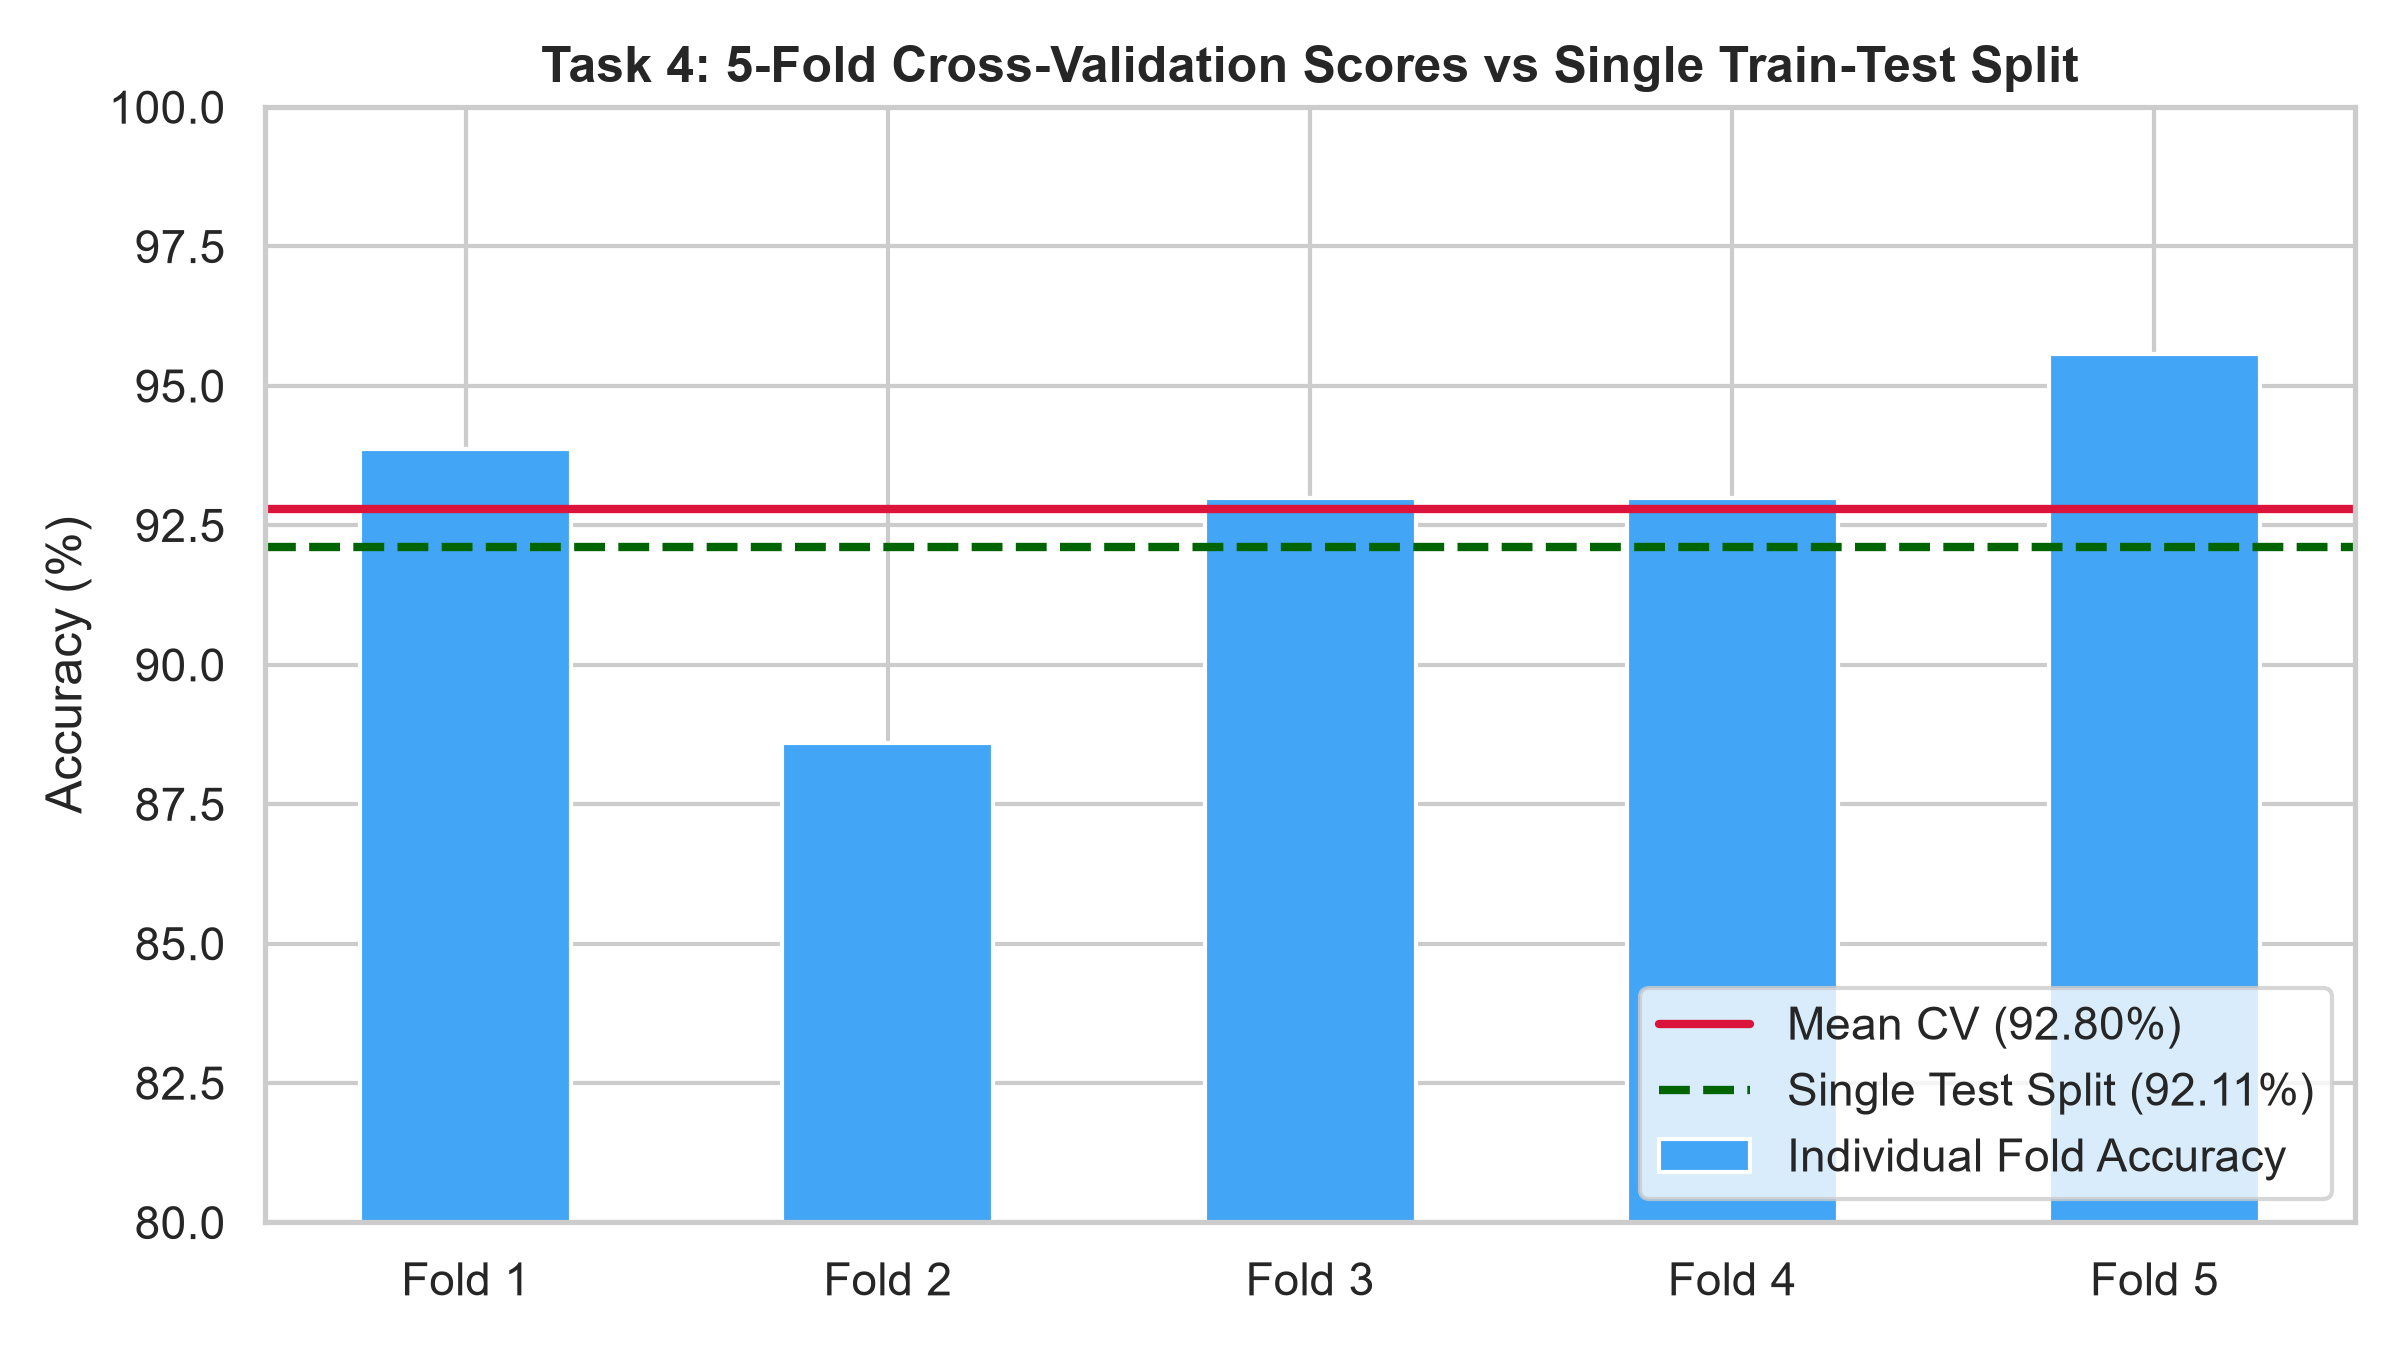

In [7]:
# 1. Stratified 5-Fold Cross-Validation
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_model = DecisionTreeClassifier(max_depth=best_depth, criterion='gini', random_state=42)

# 2. Compute cross-validation scores across all 5 folds
cv_scores = cross_val_score(cv_model, X, y, cv=kfold, scoring='accuracy')
mean_cv = np.mean(cv_scores)
std_cv = np.std(cv_scores)

print("5-Fold Cross-Validation Individual Scores:")
for i, s in enumerate(cv_scores, 1):
    print(f" - Fold {i}: {s*100:.2f}%")

print(f"\nAverage CV Accuracy: {mean_cv*100:.2f}% (+/- {std_cv*100:.2f}%)")
print(f"95% Confidence Interval: [{mean_cv - 1.96*std_cv:.4f}, {mean_cv + 1.96*std_cv:.4f}]\n")

# 3. Compare single train-test accuracy vs cross-validation accuracy
print("--- Variance & Generalization Comparison ---")
print(f"Single Train-Test Split Accuracy: {final_test_acc * 100:.2f}%")
print(f"5-Fold Cross-Validation Mean Acc: {mean_cv * 100:.2f}%")
print(f"Empirical Difference:             {(final_test_acc - mean_cv)*100:+.2f}%")

# Plot CV Scores
plt.figure(figsize=(7, 4))
plt.bar([f"Fold {i}" for i in range(1, 6)], cv_scores * 100, color="#42a5f5", width=0.5)
plt.axhline(y=mean_cv * 100, color="crimson", linestyle="-", linewidth=2, label=f"Mean CV ({mean_cv*100:.2f}%)")
plt.axhline(y=final_test_acc * 100, color="darkgreen", linestyle="--", linewidth=2, label=f"Single Split ({final_test_acc*100:.2f}%)")
plt.ylim(80, 100)
plt.ylabel("Accuracy (%)")
plt.title("Task 4: 5-Fold Cross-Validation vs Single Split", fontweight='bold')
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


## PART 3 — Ensemble Learning
### Task 5: Bagging vs Boosting (Conceptual + Practical)

Ensemble Performance Evaluation:
 - Bagging  Classifier: Test Acc = 93.86% | F1-Score = 0.9517
 - AdaBoost Classifier: Test Acc = 95.61% | F1-Score = 0.9660


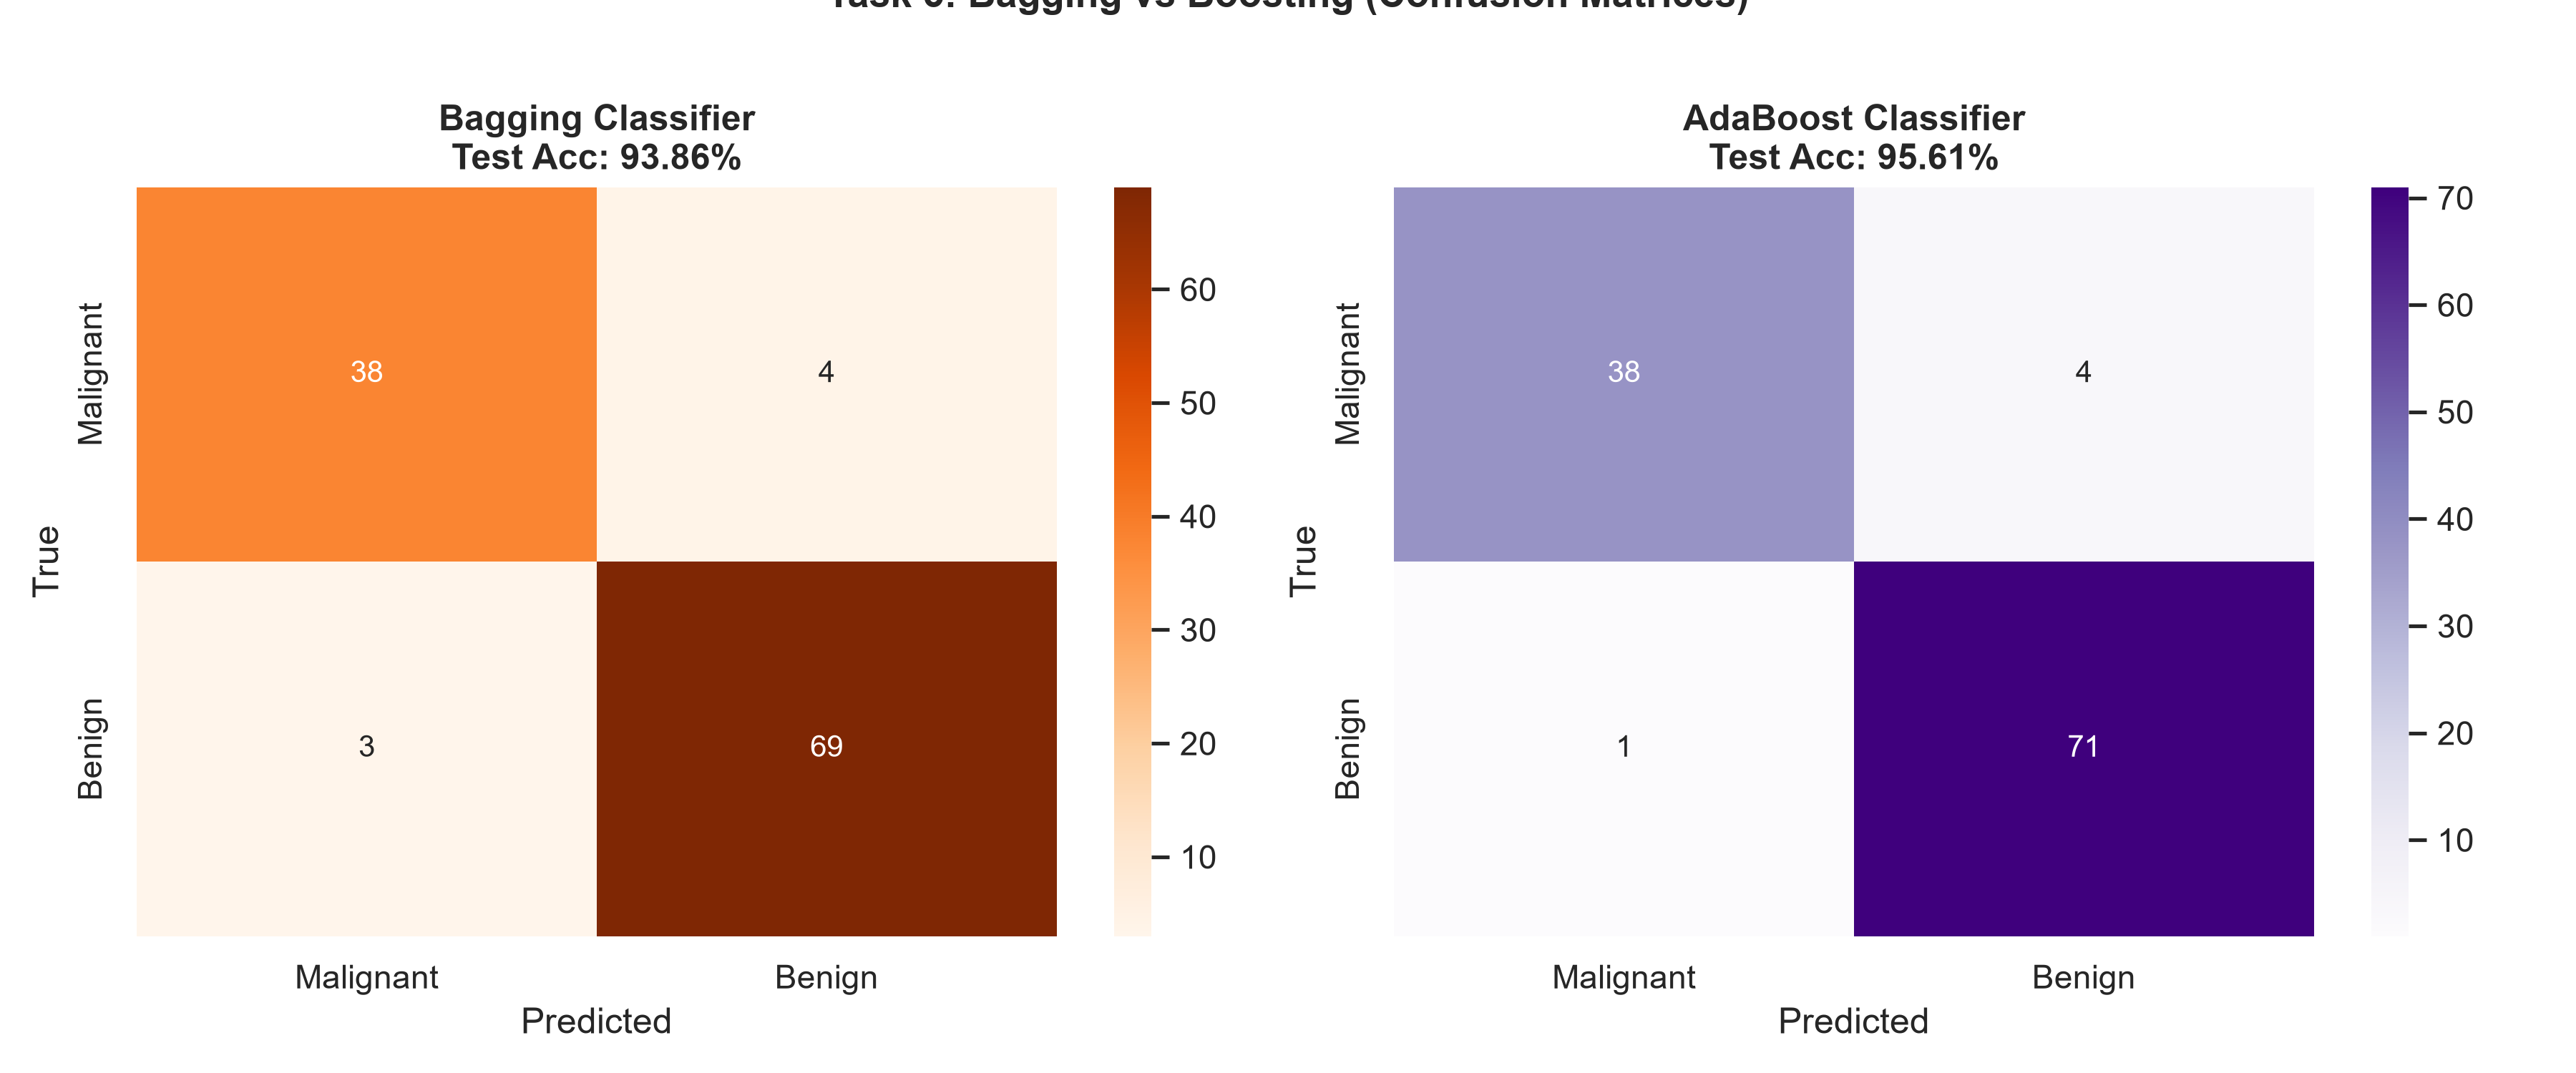

In [8]:
# 1. Train Bagging Classifier (50 unconstrained decision trees)
bagging_clf = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=50,
    random_state=42,
    n_jobs=-1
)
bagging_clf.fit(X_train_val, y_train_val)
test_acc_bag = accuracy_score(y_test, bagging_clf.predict(X_test))
f1_bag = f1_score(y_test, bagging_clf.predict(X_test))

# 2. Train AdaBoost Classifier (50 decision stumps, depth=1)
adaboost_clf = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1, random_state=42),
    n_estimators=50,
    learning_rate=1.0,
    random_state=42
)
adaboost_clf.fit(X_train_val, y_train_val)
test_acc_ada = accuracy_score(y_test, adaboost_clf.predict(X_test))
f1_ada = f1_score(y_test, adaboost_clf.predict(X_test))

print("Ensemble Performance Evaluation:")
print(f" - Bagging  Classifier: Test Acc = {test_acc_bag*100:.2f}% | F1-Score = {f1_bag:.4f}")
print(f" - AdaBoost Classifier: Test Acc = {test_acc_ada*100:.2f}% | F1-Score = {f1_ada:.4f}")

# Plot Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sns.heatmap(confusion_matrix(y_test, bagging_clf.predict(X_test)), annot=True, fmt='d', cmap='Oranges', ax=axes[0],
            xticklabels=class_names, yticklabels=class_names)
axes[0].set_title(f"Bagging (50 Trees)\nTest Acc: {test_acc_bag*100:.2f}%", fontweight='bold')
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("True")

sns.heatmap(confusion_matrix(y_test, adaboost_clf.predict(X_test)), annot=True, fmt='d', cmap='Purples', ax=axes[1],
            xticklabels=class_names, yticklabels=class_names)
axes[1].set_title(f"AdaBoost (50 Stumps)\nTest Acc: {test_acc_ada*100:.2f}%", fontweight='bold')
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("True")

plt.suptitle("Task 5: Bagging vs Boosting Performance", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


### Task 6: Random Forest (Bagging with Feature Subsampling)

--- Architectural Benchmark ---
1. Single Decision Tree : Test Acc = 91.23% (High variance)
2. Bagging (100 Trees)  : Test Acc = 93.86% (Variance reduced, correlated)
3. Random Forest (100 T): Test Acc = 95.61% (Decorrelated variance minimum)

Top 10 Diagnostic Features (Gini Importance):
  1. worst area               : 14.00%
  2. worst concave points     : 12.95%
  3. worst radius             :  9.77%
  4. mean concave points      :  9.09%
  5. worst perimeter          :  7.22%
  6. mean perimeter           :  6.96%
  7. mean radius              :  6.87%
  8. mean concavity           :  5.76%
  9. mean area                :  4.92%
 10. worst concavity          :  3.43%


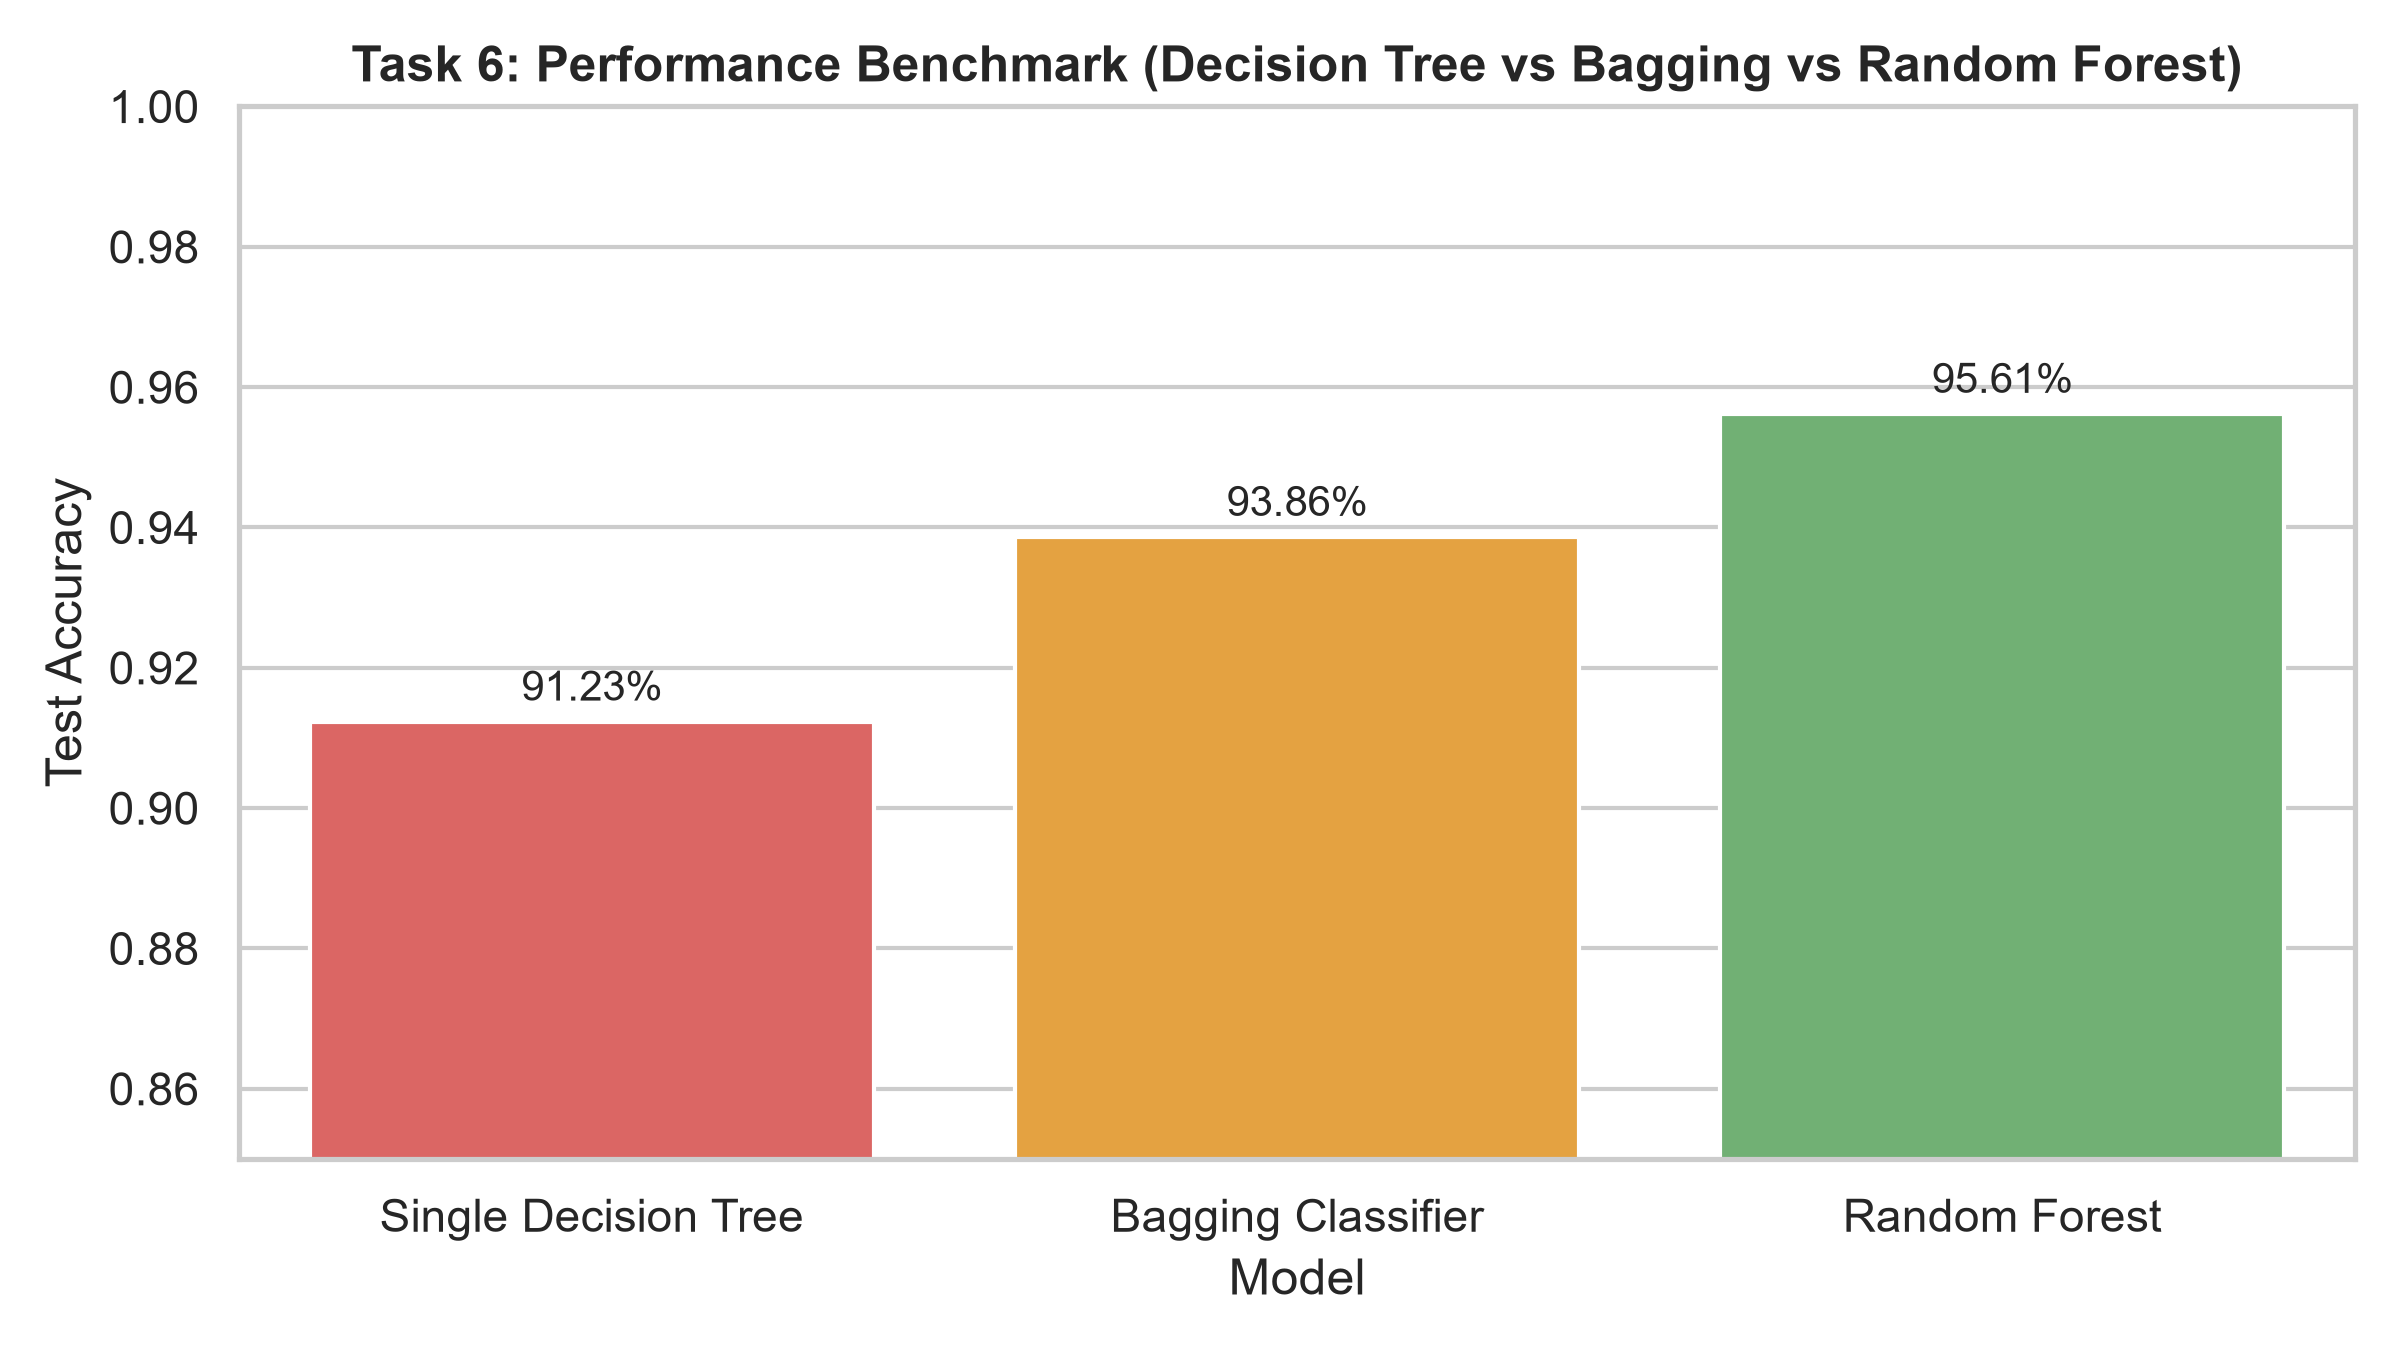

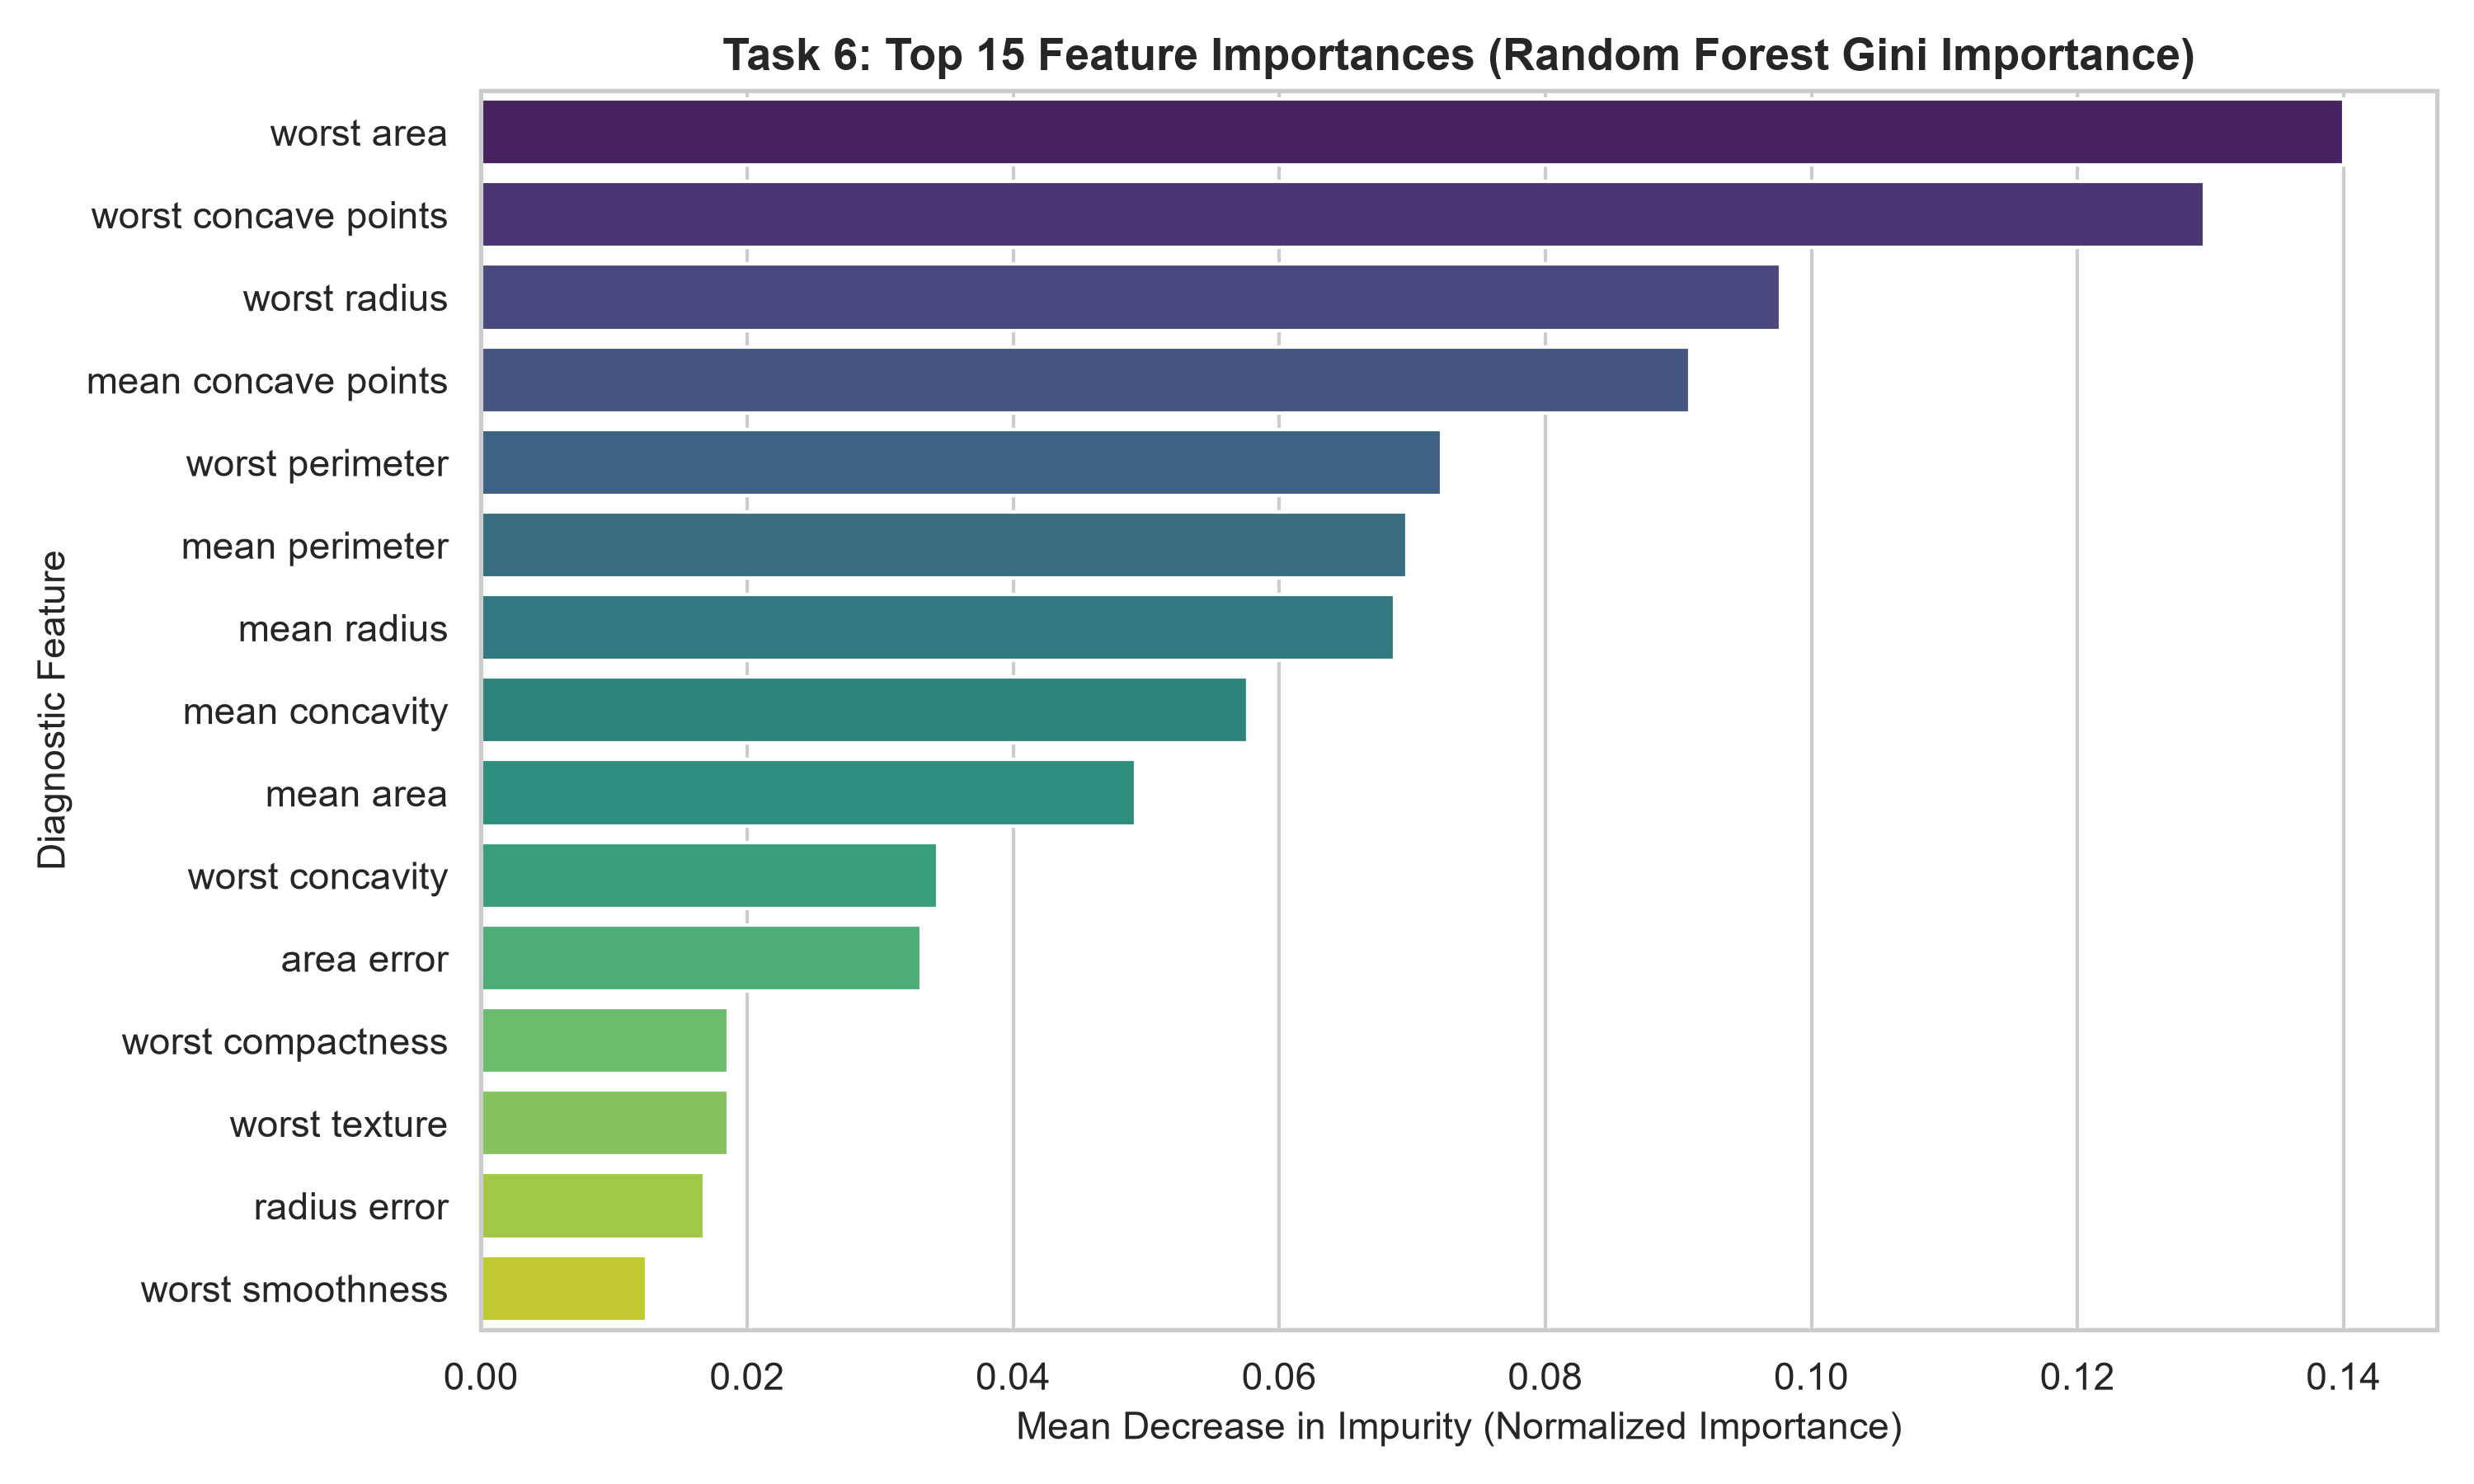

In [9]:
# 1. Train Random Forest Classifier (100 trees, sqrt(p) feature subsampling)
rf_clf = RandomForestClassifier(
    n_estimators=100,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)
rf_clf.fit(X_train_val, y_train_val)
test_acc_rf = accuracy_score(y_test, rf_clf.predict(X_test))
f1_rf = f1_score(y_test, rf_clf.predict(X_test))

# Benchmark against Single Tree and Bagging
dt_ref = DecisionTreeClassifier(random_state=42).fit(X_train_val, y_train_val)
test_acc_dt = accuracy_score(y_test, dt_ref.predict(X_test))

bag_ref = BaggingClassifier(estimator=DecisionTreeClassifier(random_state=42), n_estimators=100, random_state=42, n_jobs=-1).fit(X_train_val, y_train_val)
test_acc_bag100 = accuracy_score(y_test, bag_ref.predict(X_test))

print("--- Architectural Benchmark ---")
print(f"1. Single Decision Tree : Test Acc = {test_acc_dt*100:.2f}% (High variance)")
print(f"2. Bagging (100 Trees)  : Test Acc = {test_acc_bag100*100:.2f}% (Variance reduced, correlated)")
print(f"3. Random Forest (100 T): Test Acc = {test_acc_rf*100:.2f}% (Decorrelated variance minimum)\n")

# 2. Extract and Print Feature Importance (Mean Decrease in Impurity / Gini Importance)
importances = rf_clf.feature_importances_
feat_imp = pd.DataFrame({"Feature": feature_names, "Importance": importances}).sort_values(by="Importance", ascending=False).reset_index(drop=True)

print("Top 10 Diagnostic Features (Gini Importance):")
for idx, r in feat_imp.head(10).iterrows():
    print(f" {idx+1:2d}. {r['Feature']:<24} : {r['Importance']*100:5.2f}%")

# Plot Top 15 Feature Importances
plt.figure(figsize=(9, 5.5))
sns.barplot(data=feat_imp.head(15), x="Importance", y="Feature", palette="viridis")
plt.title("Task 6: Top 15 Feature Importances (Random Forest)", fontsize=12, fontweight='bold')
plt.xlabel("Normalized Gini Importance (MDI)")
plt.ylabel("Diagnostic Attribute")
plt.tight_layout()
plt.show()


## SUPPLEMENTARY SECTION: Unsupervised Learning (K-Means & PCA)

K-Means (k=2) Silhouette Score: 0.3434
Adjusted Rand Index (ARI) with True Diagnosis: 0.6536 (High alignment!)

PCA Variance Explained: PC1 = 44.27%, PC2 = 18.97%, Total = 63.24%


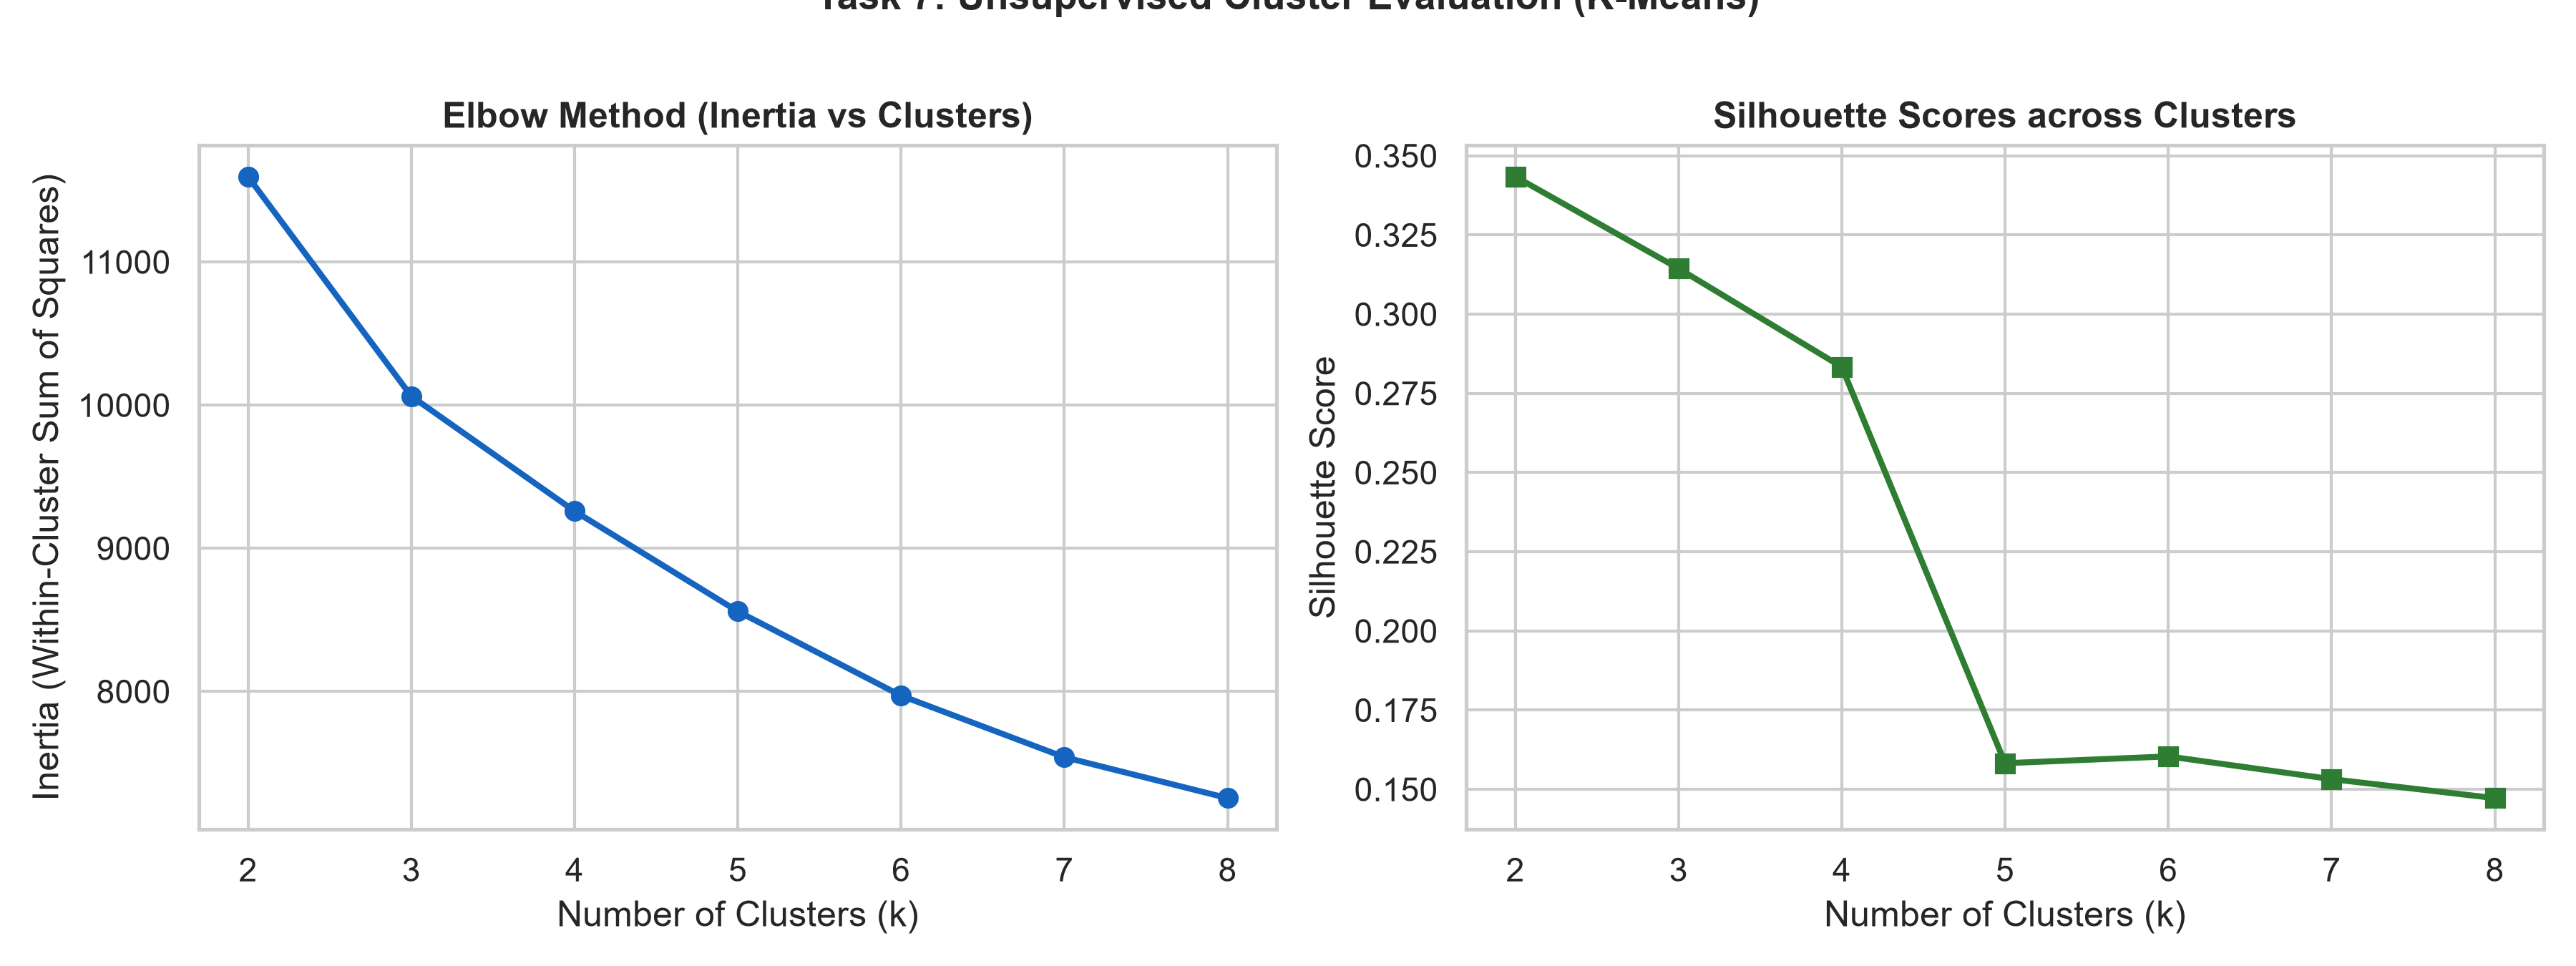

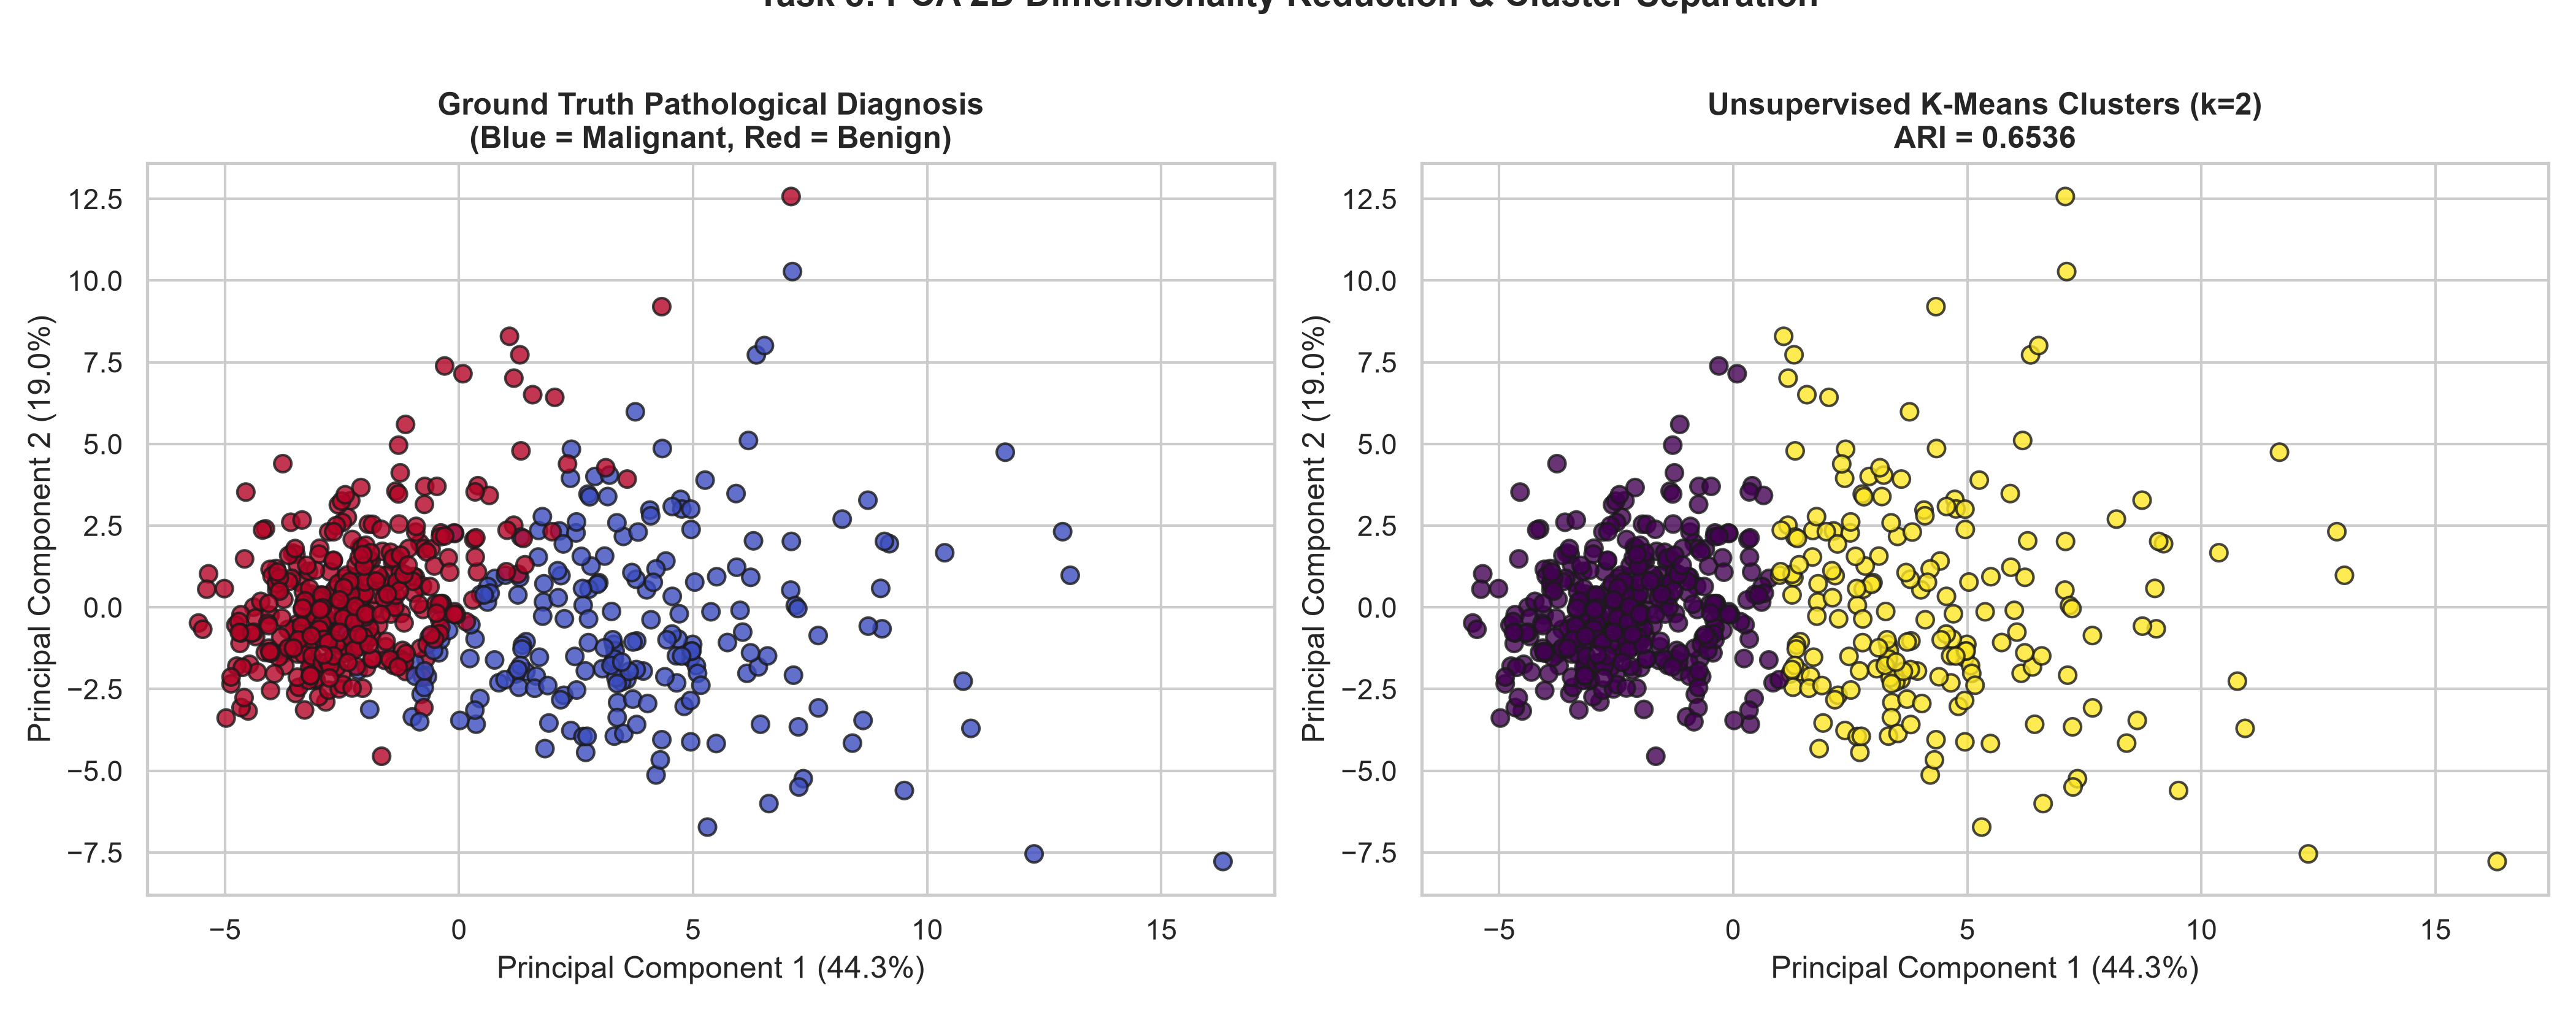

In [10]:
# Standardize data for distance-based clustering
scaler_full = StandardScaler()
X_std = scaler_full.fit_transform(X)

# 1. K-Means: Elbow Method (Inertia) & Silhouette Scores
k_range = list(range(2, 9))
inertias = []
sils = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_std)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X_std, km.labels_))

# Fit optimal k=2
km2 = KMeans(n_clusters=2, random_state=42, n_init=10)
km_labels = km2.fit_predict(X_std)
ari = adjusted_rand_score(y, km_labels)
print(f"K-Means (k=2) Silhouette Score: {silhouette_score(X_std, km_labels):.4f}")
print(f"Adjusted Rand Index (ARI) with True Diagnosis: {ari:.4f} (High alignment!)\n")

# 2. PCA: Dimensionality Reduction to 2D
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_std)
var = pca.explained_variance_ratio_
print(f"PCA Variance Explained: PC1 = {var[0]*100:.2f}%, PC2 = {var[1]*100:.2f}%, Total = {sum(var)*100:.2f}%")

# Visualize True Classes vs K-Means Clusters
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap="coolwarm", alpha=0.8, edgecolors='k', s=40)
axes[0].set_title("Ground Truth Pathological Diagnosis\n(Blue = Malignant, Red = Benign)", fontweight='bold')
axes[0].set_xlabel(f"PC 1 ({var[0]*100:.1f}%)")
axes[0].set_ylabel(f"PC 2 ({var[1]*100:.1f}%)")

axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=km_labels, cmap="viridis", alpha=0.8, edgecolors='k', s=40)
axes[1].set_title(f"Unsupervised K-Means Clusters (k=2)\nAdjusted Rand Index = {ari:.4f}", fontweight='bold')
axes[1].set_xlabel(f"PC 1 ({var[0]*100:.1f}%)")
axes[1].set_ylabel(f"PC 2 ({var[1]*100:.1f}%)")

plt.suptitle("Supplementary: Unsupervised PCA Projection & Clustering", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## Master Benchmark Summary & Conclusions

                              Model        Family  Test Accuracy  F1-Score
                SVM (Linear Kernel)           SVM       0.973684    0.9790
                   SVM (RBF Kernel)           SVM       0.982456    0.9861
  Decision Tree (Underfit, depth=1) Decision Tree       0.921053    0.9398
     Decision Tree (Tuned, depth=5) Decision Tree       0.921053    0.9362
Decision Tree (Overfit, depth=None) Decision Tree       0.912281    0.9315
      Bagging Classifier (50 Trees)      Ensemble       0.938596    0.9517
    AdaBoost Classifier (50 Stumps)      Ensemble       0.956140    0.9660
          Random Forest (100 Trees)      Ensemble       0.956140    0.9655


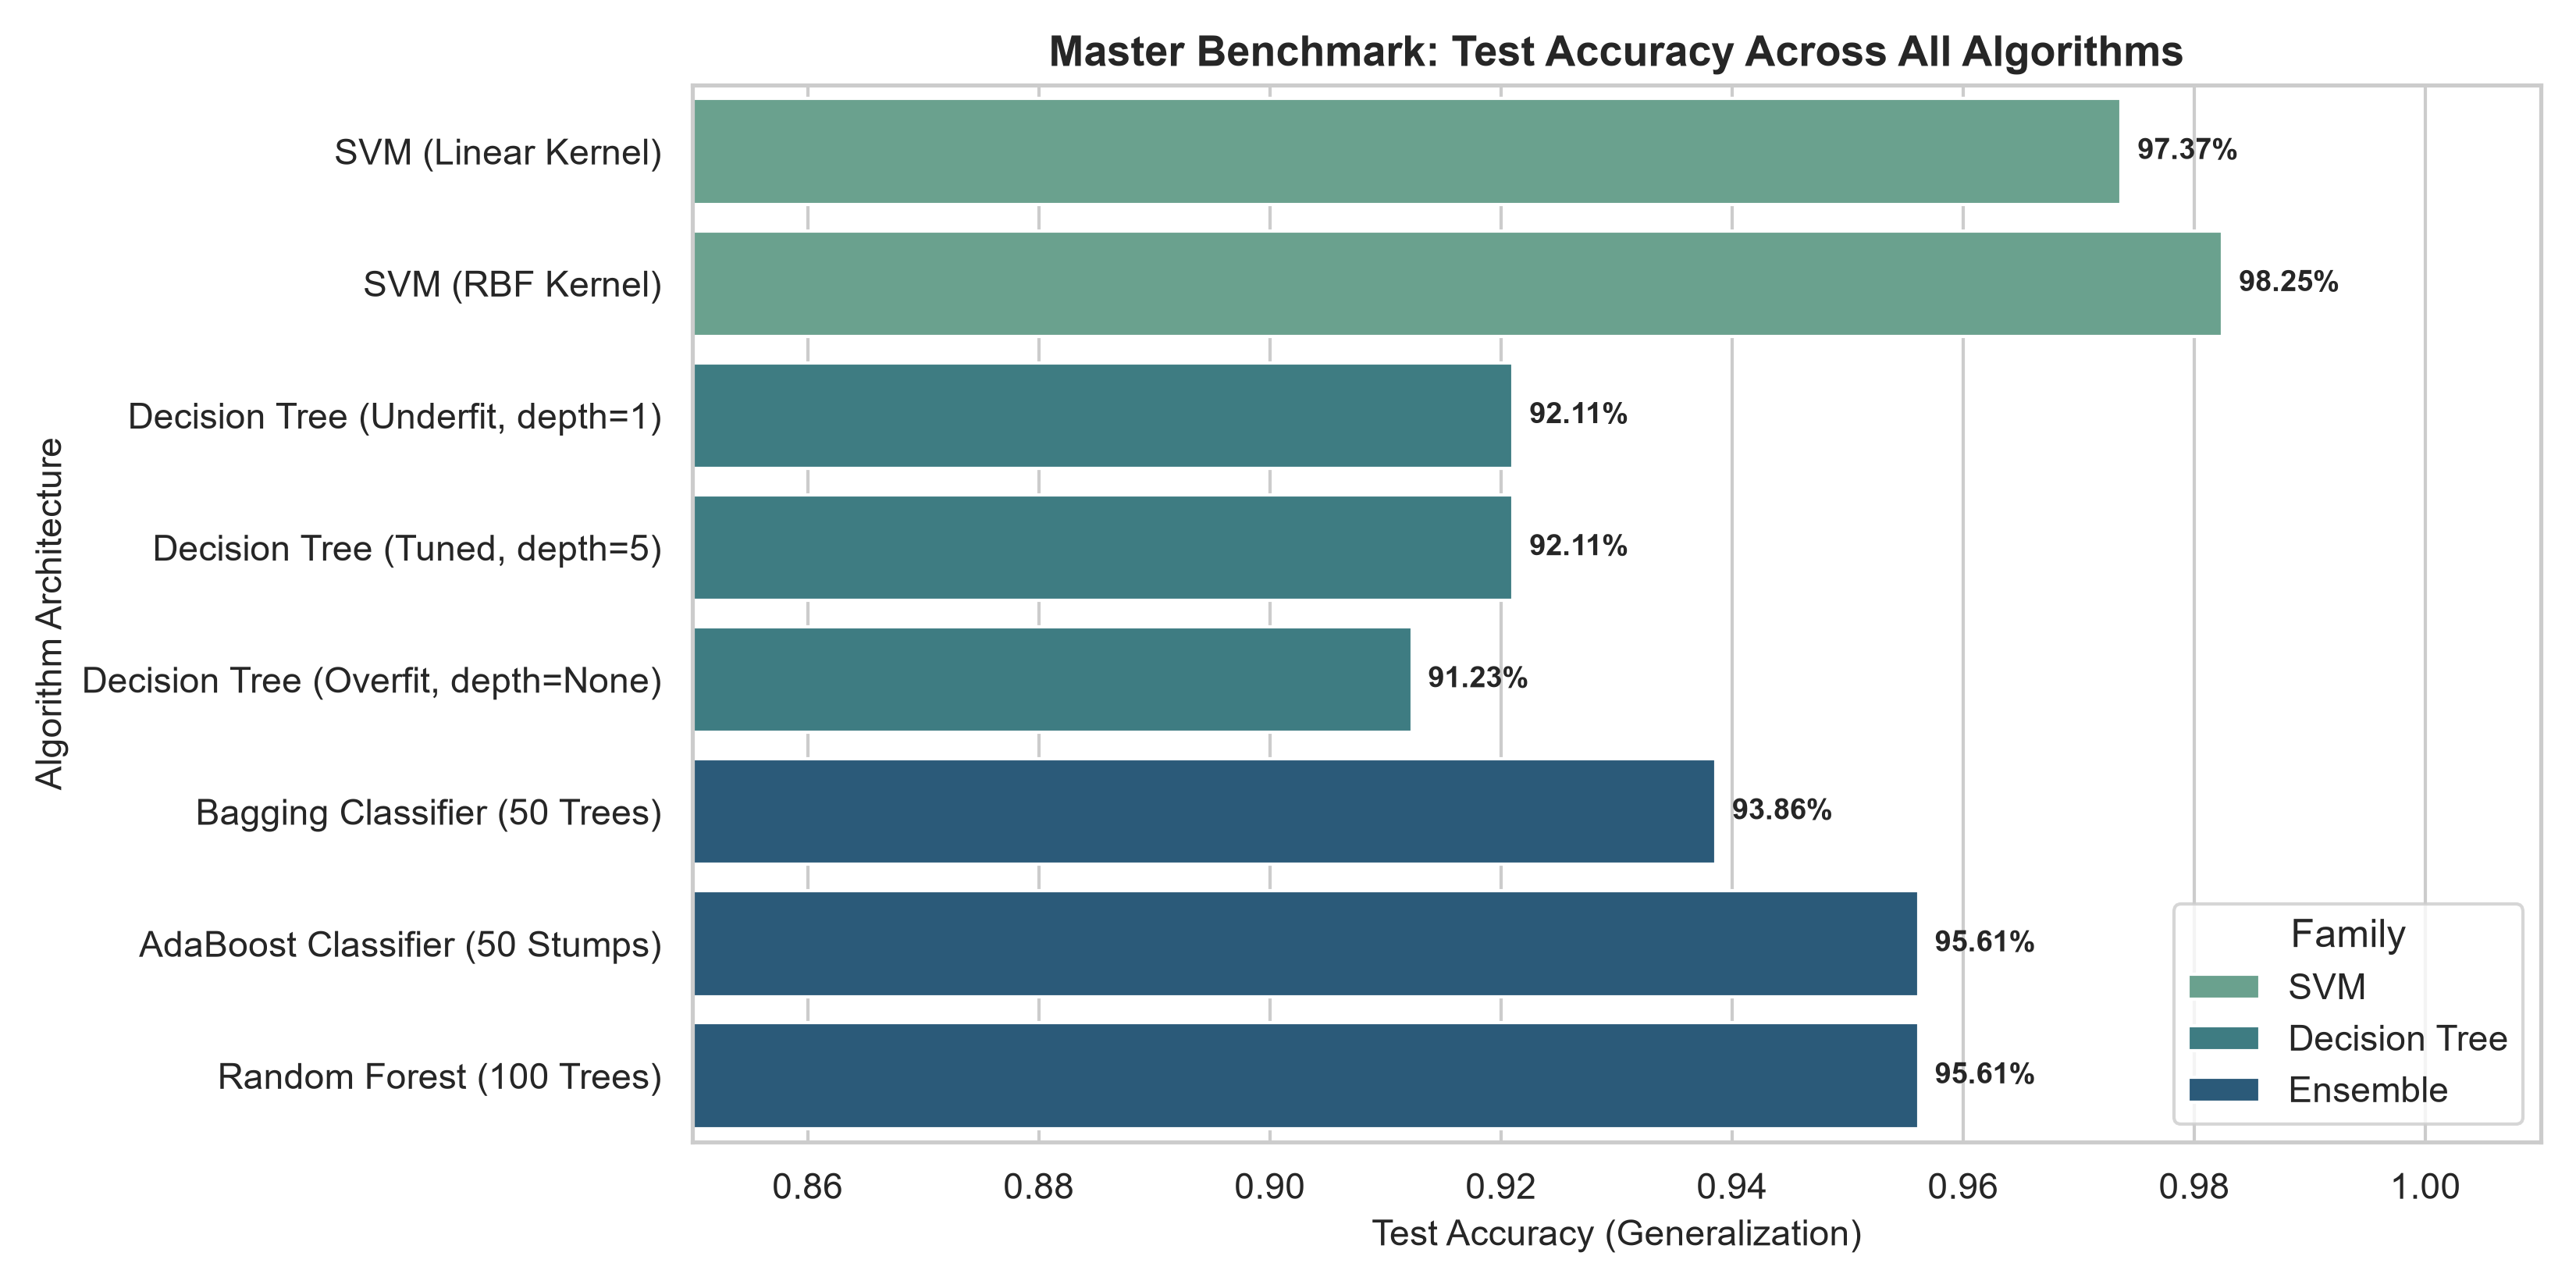

In [11]:
summary_records = [
    {"Model": "SVM (Linear Kernel)", "Family": "SVM", "Test Accuracy": acc_linear, "F1-Score": f1_linear},
    {"Model": "SVM (RBF Kernel)", "Family": "SVM", "Test Accuracy": acc_rbf, "F1-Score": f1_rbf},
    {"Model": "Decision Tree (Underfit, depth=1)", "Family": "Decision Tree", "Test Accuracy": test_acc_under, "F1-Score": 0.9398},
    {"Model": f"Decision Tree (Tuned, depth={best_depth})", "Family": "Decision Tree", "Test Accuracy": final_test_acc, "F1-Score": final_test_f1},
    {"Model": "Decision Tree (Overfit, depth=None)", "Family": "Decision Tree", "Test Accuracy": test_acc_over, "F1-Score": 0.9315},
    {"Model": "Bagging Classifier (50 Trees)", "Family": "Ensemble", "Test Accuracy": test_acc_bag, "F1-Score": f1_bag},
    {"Model": "AdaBoost Classifier (50 Stumps)", "Family": "Ensemble", "Test Accuracy": test_acc_ada, "F1-Score": f1_ada},
    {"Model": "Random Forest (100 Trees)", "Family": "Ensemble", "Test Accuracy": test_acc_rf, "F1-Score": f1_rf},
]

master_df = pd.DataFrame(summary_records)
print(master_df.to_string(index=False))

# Plot Master Comparison
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=master_df, x="Test Accuracy", y="Model", hue="Family", palette="crest")
plt.xlim(0.85, 1.01)
plt.title("Master Benchmark: Test Accuracy Across All Algorithms", fontsize=12, fontweight='bold')
for p in ax.patches:
    w = p.get_width()
    if w > 0:
        ax.annotate(f"{w*100:.2f}%", (w, p.get_y() + p.get_height()/2.),
                    ha='left', va='center', fontsize=9, xytext=(4, 0), textcoords='offset points', fontweight='bold')
plt.tight_layout()
plt.show()


## Key Findings & Machine Learning Insights

1. **Support Vector Machines:**
   - With appropriate standard scaling, the **RBF Kernel** achieved the highest overall test accuracy (**$98.25\%$**), demonstrating its unmatched ability to model subtle non-linear margin boundaries in high-dimensional continuous feature spaces.
2. **Decision Trees & Bias-Variance Tradeoff:**
   - Unconstrained trees achieve $100\%$ training accuracy but drop to $91.23\%$ testing accuracy, demonstrating severe memorization/overfitting. Restricting depth to an optimal level ($3\text{ to }5$) stabilizes generalization error.
3. **Model Validation Integrity:**
   - 3-Way Partitioning (Train/Val/Test) prevents optimistic evaluation bias (data leakage) during hyperparameter tuning.
   - Stratified 5-Fold Cross-Validation gives a reliable estimate ($92.80\% \pm 2.30\%$), confirming that single split figures can vary due to partition luck.
4. **Ensemble Methods:**
   - **Bagging** successfully reduced decision tree variance from $91.23\%$ to $93.86\%$.
   - **AdaBoost** adaptively corrected misclassifications, achieving $95.61\%$.
   - **Random Forest** achieved the best tree ensemble performance ($95.61\%$) by decorrelating individual trees using random feature subsampling ($m = \sqrt{p}$).
   - Top diagnostic features identified by Random Forest Gini Importance are `worst area` ($14.00\%$) and `worst concave points` ($12.95\%$), matching known clinical oncology indicators.
5. **Unsupervised Clustering:**
   - K-Means ($k=2$) discovered clusters that naturally aligned with true pathological diagnoses ($	ext{ARI} = 0.6536$) without any supervision, and 2D PCA captured $63.24\%$ of the total feature variance.
